# Étape 4 · Modèles

Prévision, alerte, apprentissage automatique, facteurs, formule du risque, score global, facteur dominant.

À lancer depuis le dépôt du projet, avec les données brutes placées comme le dit `01_collecte/brut/LISEZ-MOI.md`.

In [1]:
import os
import sys
import time
import unicodedata
import warnings
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
from IPython.display import Image, display
import geopandas as gpd
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import rankdata, spearmanr
from sklearn.ensemble import GradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

root = Path.cwd()
while not (root / "outils").is_dir() and root != root.parent:
    root = root.parent
os.chdir(root)
sys.path.insert(0, "outils")

import chemins
anticipation_fine = chemins.module('anticipation_fine')
solution_prevision = chemins.module('solution_prevision')

In [2]:
def show_figures(since, folders=("03_transformation/figures", "04_analyse/figures", "05_interpretation/figures", "05_interpretation/fiches"), limit=8):
    views = sorted((p for d in folders for p in Path(d).glob("*.png") if p.stat().st_mtime >= since), key=lambda p: p.name)
    for p in views[:limit]:
        print(p)
        display(Image(filename=str(p), width=760))

## 1. Prévision 2025/26, alerte d'escalade, test de l'hypothèse

`04_analyse/Biiga_04-analyse_D1_scientist_script-prevision-hypothese_v1.py`

In [3]:
YEARS = [f"{y}-{y + 1}" for y in range(2015, 2025)]
SHORT = {y: y[2:4] + "/" + y[7:] for y in YEARS + ["2025-2026", "2026-2027"]}
EN = {"Central-East": "Centre-Est", "Central-North": "Centre-Nord", "Central-South": "Centre-Sud",
      "Central-West": "Centre-Ouest", "East": "Est", "North": "Nord", "Upper-Basins": "Hauts-Bassins",
      "Waterfalls": "Cascades", "Central-Plateau": "Plateau-Central", "South-West": "Sud-Ouest"}
RNG = np.random.default_rng(2026)

In [4]:
def key(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return "".join(ch for ch in s.upper() if ch.isalnum())

In [5]:
def school_year(dt):
    start = dt.year if dt.month >= 10 else dt.year - 1
    return f"{start}-{start + 1}"

In [6]:
def main():
    pd.set_option("display.width", 220)
    panel = pd.read_csv(chemins.path("panel_region_annee.csv"))
    p = panel[panel.region != "NATIONAL"].copy()
    p["cle"] = p.region.map(key)
    names2025 = pd.read_csv(chemins.path("panel_region_annee_2025.csv")).drop_duplicates("region").set_index("region").region_2025
    acled = pd.read_csv(chemins.path("acled_region_annee.csv"))
    pov = pd.read_csv(chemins.path("pauvrete_ehcvm_2021_regions.csv"))
    pov["cle"] = pov.region.map(key)
    p = p.merge(acled, on=["cle", "annee"], how="left").merge(
        pov[["cle", "incidence_pauvrete_2021_pct"]], on="cle", how="left").sort_values(["region", "annee"])
    assert p.incidents.notna().all() and p.incidence_pauvrete_2021_pct.notna().all()
    g = p.groupby("region")
    p["dTAP_next"] = g.TAP_T.shift(-1) - p.TAP_T
    p["dlog_eleves_next"] = np.log(g.eleves_T.shift(-1) / p.eleves_T)
    p["dlog_ecoles_next"] = np.log(g.ecoles.shift(-1) / p.ecoles)
    p["l_inc"] = np.log1p(p.incidents)

    print("=== A. Prévision du TAP 2025/26 : « comme l'an passé » avec fourchette à 80 % ===")
    ch = p.dropna(subset=["dTAP_next"])
    cover = []
    for ty in YEARS[3:-1]:
        past = ch[ch.annee < ty].dTAP_next
        lo, hi = past.quantile(0.10), past.quantile(0.90)
        test = ch[ch.annee == ty]
        inside = ((test.dTAP_next >= lo) & (test.dTAP_next <= hi)).mean()
        cover.append({"annee_predite": SHORT[YEARS[YEARS.index(ty) + 1]], "n_passe": len(past),
                      "bas": round(lo, 1), "haut": round(hi, 1), "couverture_%": round(inside * 100)})
    cover = pd.DataFrame(cover)
    print(cover.to_string(index=False))
    print(f"Couverture moyenne : {cover['couverture_%'].mean():.0f} % (attendu : 80 %)")
    lo, hi = ch.dTAP_next.quantile(0.10), ch.dTAP_next.quantile(0.90)
    pop = pd.read_csv(chemins.raw("externe/hdx_cod_ps/bfa_admpop_adm2_2024.csv"), encoding="utf-8-sig")
    pop["cle"] = pop.ADM1_FR.map(key)
    pop11 = (pop.groupby("cle").T_10_14.sum() / 5).rename("enfants_11_ans_approx")
    last = p[p.annee == "2024-2025"].set_index("cle")
    fc = pd.DataFrame({
        "region": last.region, "region_2025": last.region.map(names2025),
        "TAP_24_25": last.TAP_T, "prevision_25_26": last.TAP_T,
        "fourchette_basse": (last.TAP_T + lo).clip(lower=0), "fourchette_haute": last.TAP_T + hi,
    }).join(pop11)
    fc["enfants_hors_CM2_estimes"] = ((1 - fc.TAP_24_25 / 100).clip(lower=0) * fc.enfants_11_ans_approx).round(-2)
    print(f"Fourchette appliquée : {lo:+.1f} à {hi:+.1f} points autour du TAP 2024/25")

    print("\n=== B. Alerte d'escalade (incidents ≥ 1,5 × l'année d'avant, et ≥ 30) ===")
    p["inc_prev"] = g.incidents.shift()
    p["alerte"] = (p.incidents >= 1.5 * p.inc_prev) & (p.incidents >= 30)
    hist = p.dropna(subset=["dlog_eleves_next", "inc_prev"])
    drop = hist.dlog_eleves_next < np.log(0.95)
    a, n = hist.alerte, len(hist)
    print(f"Historique ({n} régions-années) : {int(a.sum())} alertes ; "
          f"baisse d'effectifs de plus de 5 % l'année suivante dans {int((a & drop).sum())} cas sur {int(a.sum())} "
          f"({(a & drop).sum() / max(a.sum(), 1) * 100:.0f} %), contre {(~a & drop).sum() / (~a).sum() * 100:.0f} % sans alerte.")
    print(f"Baisses de plus de 5 % précédées d'une alerte : {int((a & drop).sum())} sur {int(drop.sum())}")
    print(hist[a][["region", "annee", "inc_prev", "incidents", "dlog_eleves_next"]].assign(
        variation_eleves_pct=lambda x: ((np.exp(x.dlog_eleves_next) - 1) * 100).round(1)).drop(
        columns="dlog_eleves_next").to_string(index=False))
    full = acled.copy()
    full = full.sort_values(["cle", "annee"])
    full["inc_prev"] = full.groupby("cle").incidents.shift()
    full["alerte"] = (full.incidents >= 1.5 * full.inc_prev) & (full.incidents >= 30)
    for yr, label in [("2024-2025", "rentrée 2025/26"), ("2025-2026", "rentrée 2026/27")]:
        cur = full[full.annee == yr].set_index("cle")
        col = f"incidents_{SHORT[yr].replace('/', '_')}"
        fc[col] = cur.incidents
        fc[f"alerte_{label.split()[1].replace('/', '_')}"] = cur.alerte
    fc["profil"] = None
    typology = pd.read_csv(chemins.path("P2_typologie_regions.csv"))
    typology["cle"] = typology.region.map(key)
    prof = {1: "Choc puis reprise partielle", 2: "Effondrement", 3: "Érosion", 4: "Stabilité / accueil"}
    fc["profil"] = typology.set_index("cle").groupe_k4.map(prof)
    fc = fc.sort_values("TAP_24_25")
    fc.round(1).to_csv(chemins.path("P9_prevision_2025_26_alerte.csv"))
    print("\n--- Tableau de prévision et d'alerte ---")
    print(fc.drop(columns=["region", "enfants_11_ans_approx"]).round(1).to_string())

    print("\n=== C. Hypothèse : l'insécurité pèse-t-elle plus là où la pauvreté est forte ? ===")
    m = p.dropna(subset=["dTAP_next"]).copy()
    m["pauv"] = (m.incidence_pauvrete_2021_pct - m.incidence_pauvrete_2021_pct.mean()) / 10
    m["inc_c"] = m.l_inc - m.l_inc.mean()
    m["inter"] = m.inc_c * m.pauv

    def fit(df, cols):
        X = np.c_[np.ones(len(df)), df[cols].values]
        return np.linalg.lstsq(X, df.dTAP_next.values, rcond=None)[0]

    add, inter = ["inc_c", "pauv"], ["inc_c", "pauv", "inter"]
    b_add, b_int = fit(m, add), fit(m, inter)
    regions = m.region.unique()
    boots = []
    for _ in range(2000):
        pick = RNG.choice(regions, size=len(regions), replace=True)
        bs = pd.concat([m[m.region == r] for r in pick])
        boots.append(fit(bs, inter))
    boots = np.array(boots)
    names = ["constante", "insécurité (log incidents, centré)", "pauvreté (par 10 points)", "insécurité × pauvreté"]
    print("Modèle avec interaction, variation du TAP l'année suivante (points) :")
    for i, nme in enumerate(names):
        lo_b, hi_b = np.percentile(boots[:, i], [2.5, 97.5])
        print(f"  {nme:38s} {b_int[i]:+6.2f}   IC 95 % [{lo_b:+.2f} ; {hi_b:+.2f}]")
    rows = []
    for ty in sorted(m.annee.unique())[3:]:
        tr, te = m[m.annee < ty], m[m.annee == ty]
        for name_, cols in [("additif", add), ("interaction", inter)]:
            b = fit(tr, cols)
            pred = np.c_[np.ones(len(te)), te[cols].values] @ b
            rows.append({"modele": name_, "annee": ty, "erreur": np.abs(te.dTAP_next - pred).mean()})
        rows.append({"modele": "comme l'an passé", "annee": ty, "erreur": np.abs(te.dTAP_next).mean()})
    oos = pd.DataFrame(rows).groupby("modele").erreur.mean().round(2)
    print("Erreur moyenne sur années non vues (points) :", oos.to_dict())
    cs = p[p.annee.isin(["2021-2022", "2024-2025"])].pivot_table(index="region", columns="annee", values="TAP_T")
    cs["variation_TAP"] = cs["2024-2025"] - cs["2021-2022"]
    inc = p[p.annee.isin(["2021-2022", "2022-2023", "2023-2024"])].groupby("region").incidents.sum()
    cs = cs.join(inc.rename("incidents_21_24")).join(pov.set_index("region").incidence_pauvrete_2021_pct.rename("pauvrete_2021"))
    cs = cs.sort_values("variation_TAP")
    cs.round(1).to_csv(chemins.path("P10_hypothese_transversale.csv"))
    print("\nVue transversale 2021/22 → 2024/25 :")
    print(cs.round(1).to_string())
    print(f"r(variation TAP, pauvreté) = {np.corrcoef(cs.variation_TAP, cs.pauvrete_2021)[0, 1]:+.2f} ; "
          f"r(variation TAP, log incidents) = {np.corrcoef(cs.variation_TAP, np.log1p(cs.incidents_21_24))[0, 1]:+.2f} (n = 13)")

    print("\n=== D. Attaques contre l'éducation (Insecurity Insight) ===")
    e = pd.read_excel(chemins.raw("externe/hdx_insecurity_insight/education_in_danger_2017_2026.xlsx"))
    print(f"{len(e)} incidents ; région non renseignée : {int(e['Admin 1'].isna().sum())}")
    e = e.dropna(subset=["Admin 1"])
    e["cle"] = e["Admin 1"].map(lambda x: key(EN.get(x, x)))
    e["annee"] = pd.to_datetime(e.Date).map(school_year)
    ea = e.groupby(["cle", "annee"]).size().rename("attaques_education")
    ea.reset_index().sort_values(["cle", "annee"]).to_csv(chemins.path("P10_attaques_education_region_annee.csv"), index=False)
    q = p.join(ea, on=["cle", "annee"])
    q["attaques_education"] = q.attaques_education.fillna(0)
    q = q[(q.annee >= "2016-2017")].dropna(subset=["dlog_ecoles_next"])
    for col in ["attaques_education", "incidents"]:
        r = np.corrcoef(np.log1p(q[col]), q.dlog_ecoles_next)[0, 1]
        print(f"  r(log {col} d'une année, variation des écoles l'année suivante) = {r:+.2f} (n = {len(q)})")

In [7]:
run_prevision_hypothese = main
t0 = time.time()
sys.argv = ['prevision_hypothese.py']
run_prevision_hypothese()
show_figures(t0)

=== A. Prévision du TAP 2025/26 : « comme l'an passé » avec fourchette à 80 % ===
annee_predite  n_passe  bas  haut  couverture_%
        19/20       39 -5.0   4.8            77
        20/21       52 -5.5   4.5            62
        21/22       65 -5.6   5.7            69
        22/23       78 -5.6   6.1            46
        23/24       91 -6.6   5.3           100
        24/25      104 -6.3   4.9            85
Couverture moyenne : 73 % (attendu : 80 %)
Fourchette appliquée : -6.5 à +4.4 points autour du TAP 2024/25

=== B. Alerte d'escalade (incidents ≥ 1,5 × l'année d'avant, et ≥ 30) ===
Historique (104 régions-années) : 22 alertes ; baisse d'effectifs de plus de 5 % l'année suivante dans 12 cas sur 22 (55 %), contre 9 % sans alerte.
Baisses de plus de 5 % précédées d'une alerte : 12 sur 19
           region     annee  inc_prev  incidents  variation_eleves_pct
BOUCLE DU MOUHOUN 2018-2019       7.0         32                  -7.6
BOUCLE DU MOUHOUN 2019-2020      32.0         51   

Modèle avec interaction, variation du TAP l'année suivante (points) :
  constante                               -0.88   IC 95 % [-1.18 ; -0.49]
  insécurité (log incidents, centré)      -1.01   IC 95 % [-1.41 ; -0.62]
  pauvreté (par 10 points)                -0.18   IC 95 % [-0.56 ; +0.33]
  insécurité × pauvreté                   +0.14   IC 95 % [-0.38 ; +0.25]
Erreur moyenne sur années non vues (points) : {'additif': 4.24, "comme l'an passé": 4.11, 'interaction': 4.46}

Vue transversale 2021/22 → 2024/25 :
                   2021-2022  2024-2025  variation_TAP  incidents_21_24  pauvrete_2021
region                                                                                
CENTRE-NORD             46.4       27.7          -18.7              702           49.6
BOUCLE DU MOUHOUN       53.4       37.2          -16.2              568           56.1
CASCADES                62.6       49.4          -13.2              197           36.9
NORD                    59.5       46.4          -

## 2. Figures de la prévision

`04_analyse/Biiga_04-analyse_D1_scientist_script-figures-prevision_v1.py`

In [8]:
BLUE, BAND, WARN = "#2a78d6", "#b7d3f6", "#fab219"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

In [9]:
def fr(v, nd=0):
    return f"{v:,.{nd}f}".replace(",", " ").replace(".", ",")

In [10]:
def header(fig, main, sub):
    fig.text(0.01, 0.985, main, fontsize=13, fontweight="bold", color=INK, va="top")
    fig.text(0.01, 0.94, sub, fontsize=9.5, color=INK2, va="top")
    fig.text(0.01, 0.01, "Sources : données du Data Challenge Burkina (DGESS) ; ACLED et INSD via HDX ; "
             "INSD, EHCVM 2021. Calculs de l'équipe.", fontsize=7.5, color=MUTED)

In [11]:
def main():
    fc = pd.read_csv(chemins.path("P9_prevision_2025_26_alerte.csv")).sort_values("TAP_24_25", ascending=False)
    fig, ax = plt.subplots(figsize=(10, 6.4))
    fig.subplots_adjust(top=0.82, bottom=0.12, left=0.20, right=0.80)
    y = np.arange(len(fc))
    ax.hlines(y, fc.fourchette_basse, fc.fourchette_haute, color=BAND, linewidth=7, zorder=1,
              label="Fourchette à 80 % pour 2025/26")
    ax.scatter(fc.TAP_24_25, y, s=46, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3,
               label="TAP 2024/25 = prévision 2025/26")
    ax.set_yticks(y)
    ax.set_yticklabels(fc.region_2025)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, 100)
    ax.set_xlabel("Taux d'achèvement du primaire (%)")
    for i, (_, r) in enumerate(fc.iterrows()):
        ax.text(101.5, i, f"{fr(r.enfants_hors_CM2_estimes)}", va="center", fontsize=8.5, color=INK2,
                transform=ax.get_yaxis_transform() if False else ax.transData, clip_on=False)
        if r.alerte_2026_27:
            ax.annotate("⚠ alerte 2026/27", (r.fourchette_haute, i), xytext=(8, 0), textcoords="offset points",
                        va="center", fontsize=8.5, color=INK, fontweight="bold")
            ax.scatter([r.fourchette_haute + 1.2], [i], s=0)
    ax.text(101.5, len(fc) - 0.2, "Enfants ≈ 11 ans\nhors CM2 (est.)", fontsize=8, color=INK2, va="bottom",
            clip_on=False)
    ax.legend(loc="lower left", fontsize=8.5)
    header(fig, "Anticiper : prévision prudente 2025/26 et alerte d'escalade",
           "La prévision reprend le taux 2024/25 ; la fourchette vient des variations passées (elle a couvert 73 % des cas,\n"
           "46 % l'année du choc). Alerte : incidents d'oct. 2025 à sept. 2026 ≥ 1,5 fois ceux de l'année d'avant, et ≥ 30.")
    fig.savefig(chemins.path("09_prevision_alerte.png"), dpi=200)
    plt.close(fig)

    cs = pd.read_csv(chemins.path("P10_hypothese_transversale.csv"))
    names = pd.read_csv(chemins.path("panel_region_annee_2025.csv")).drop_duplicates("region").set_index("region").region_2025
    fig, ax = plt.subplots(figsize=(9, 6.2))
    fig.subplots_adjust(top=0.82, bottom=0.12, left=0.10, right=0.96)
    size = 20 + cs.incidents_21_24 / 3
    ax.scatter(cs.pauvrete_2021, cs.variation_TAP, s=size, color=BLUE, alpha=0.8, edgecolor=SURFACE, linewidth=1.5)
    offsets = {"SAHEL": (-10, 8, "right"), "CENTRE-EST": (-8, 6, "right"), "HAUTS-BASSINS": (8, -10, "left"),
               "SUD-OUEST": (-8, 6, "right"), "PLATEAU CENTRAL": (8, -10, "left")}
    for _, r in cs.iterrows():
        dx, dy, ha = offsets.get(r.region, (7, 4, "left"))
        ax.annotate(names[r.region], (r.pauvrete_2021, r.variation_TAP), xytext=(dx, dy), textcoords="offset points",
                    fontsize=8, color=INK2, ha=ha)
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: fr(v, 1)))
    ax.axhline(0, color=AXIS, linewidth=0.8)
    ax.set_xlabel("Pauvreté 2021 (% de la population sous le seuil, EHCVM)")
    ax.set_ylabel("Variation du taux d'achèvement 2021/22 → 2024/25 (points)")
    for v, lab in [(50, "50"), (500, "500"), (1200, "1 200")]:
        ax.scatter([], [], s=20 + v / 3, color=BLUE, alpha=0.8, label=f"{lab} incidents")
    ax.legend(loc="lower left", fontsize=8.5, title="Incidents 2021-2024", title_fontsize=8.5, labelspacing=1.2)
    header(fig, "Aucun effet de cumul insécurité × pauvreté détecté à l'échelle régionale",
           "Toutes les régions reculent, riches ou pauvres. Sur le panel de 104 régions-années, l'interaction insécurité × pauvreté\n"
           "n'est pas significative (IC 95 % de −0,38 à +0,25) et prédit moins bien que la règle « comme l'an passé ».")
    fig.savefig(chemins.path("10_hypothese_insecurite_pauvrete.png"), dpi=200)
    plt.close(fig)
    print("2 figures écrites")

2 figures écrites
04_analyse/figures/Biiga_04-analyse_D1_scientist_figure-09-prevision-alerte_v1.png


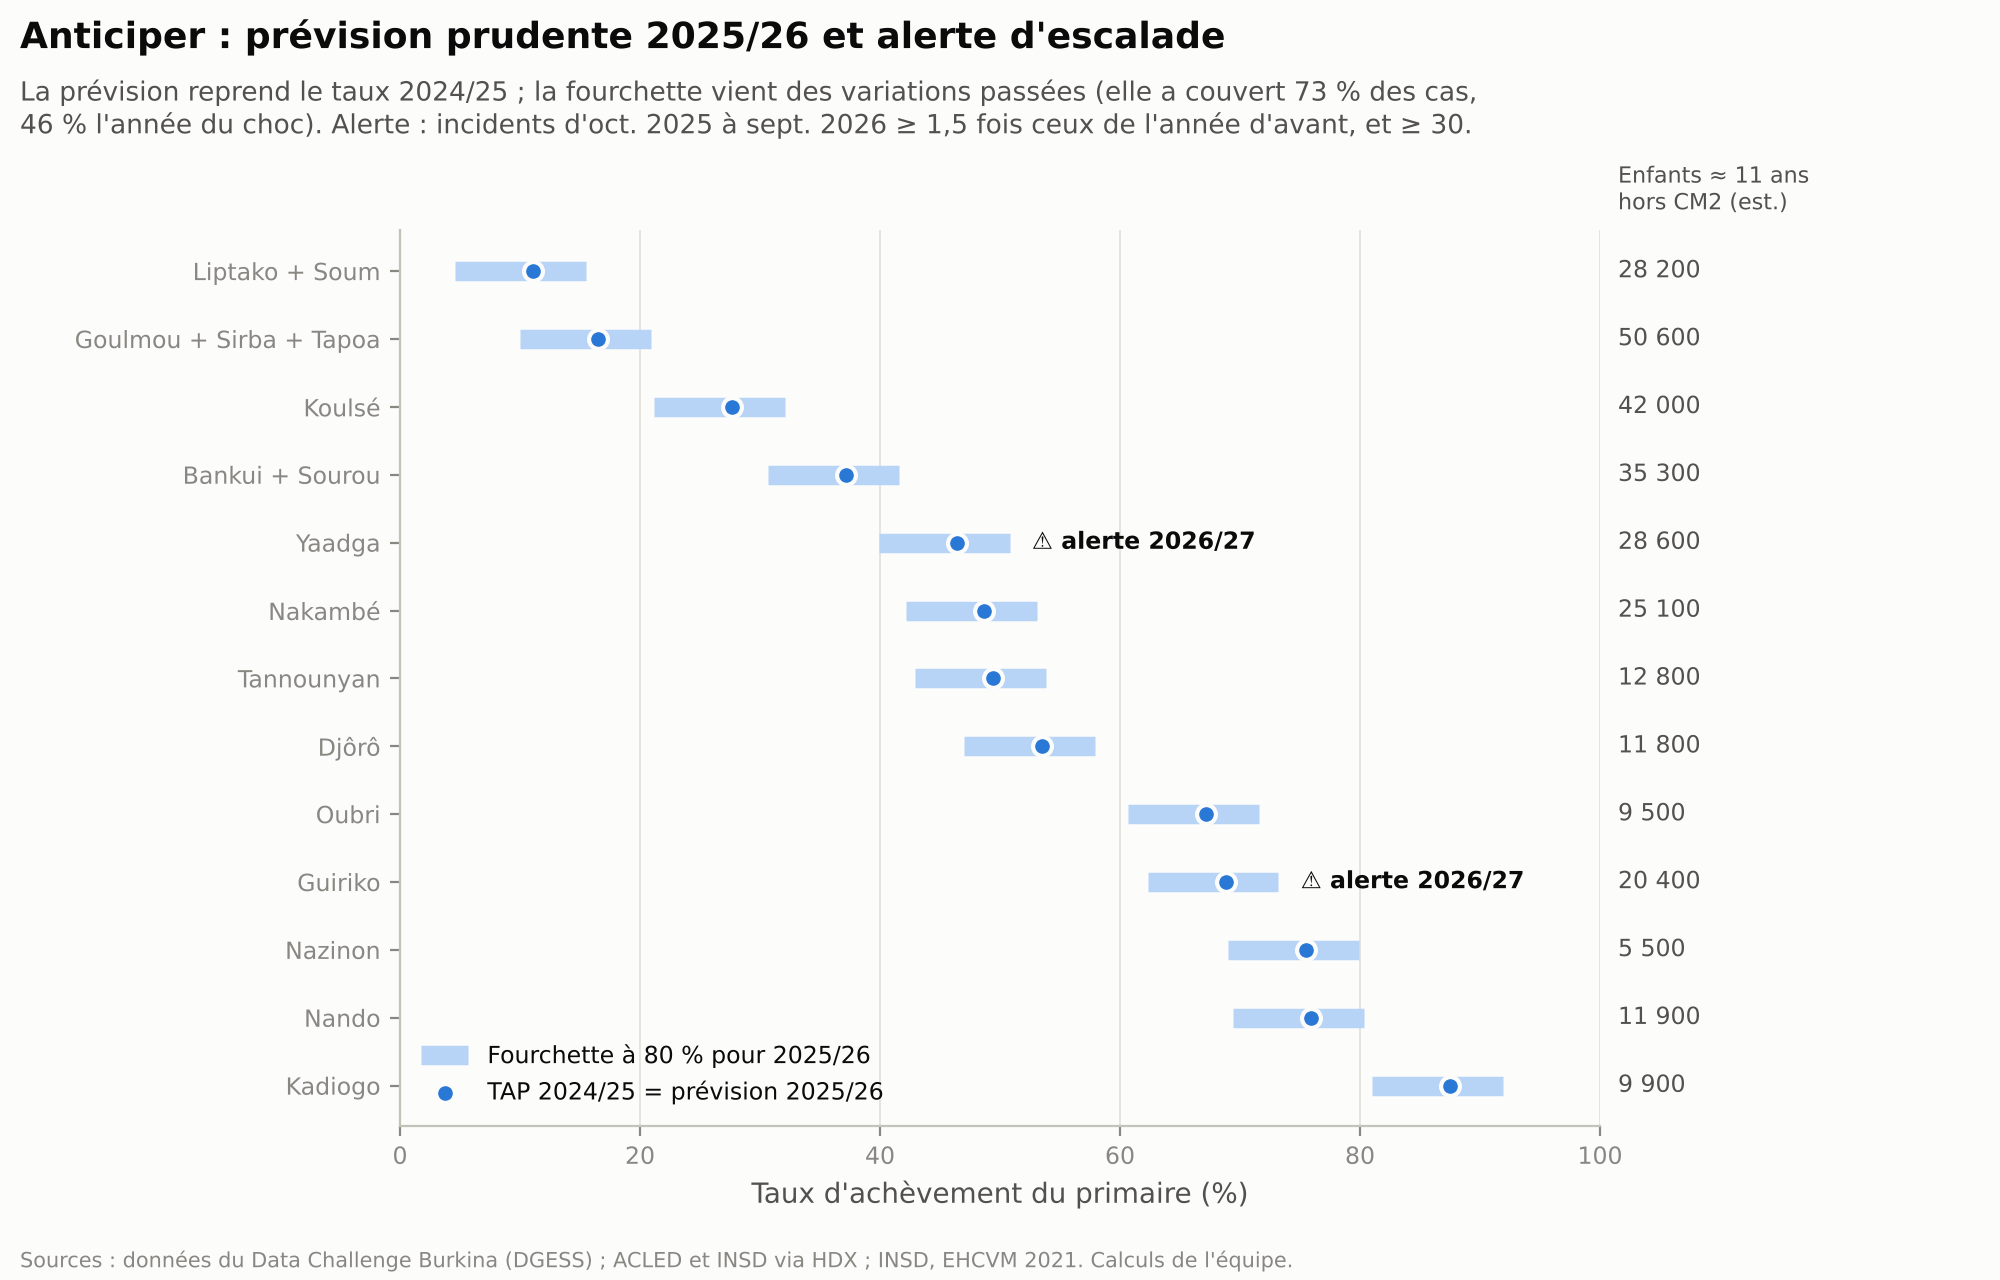

04_analyse/figures/Biiga_04-analyse_D1_scientist_figure-10-hypothese-insecurite-pauvrete_v1.png


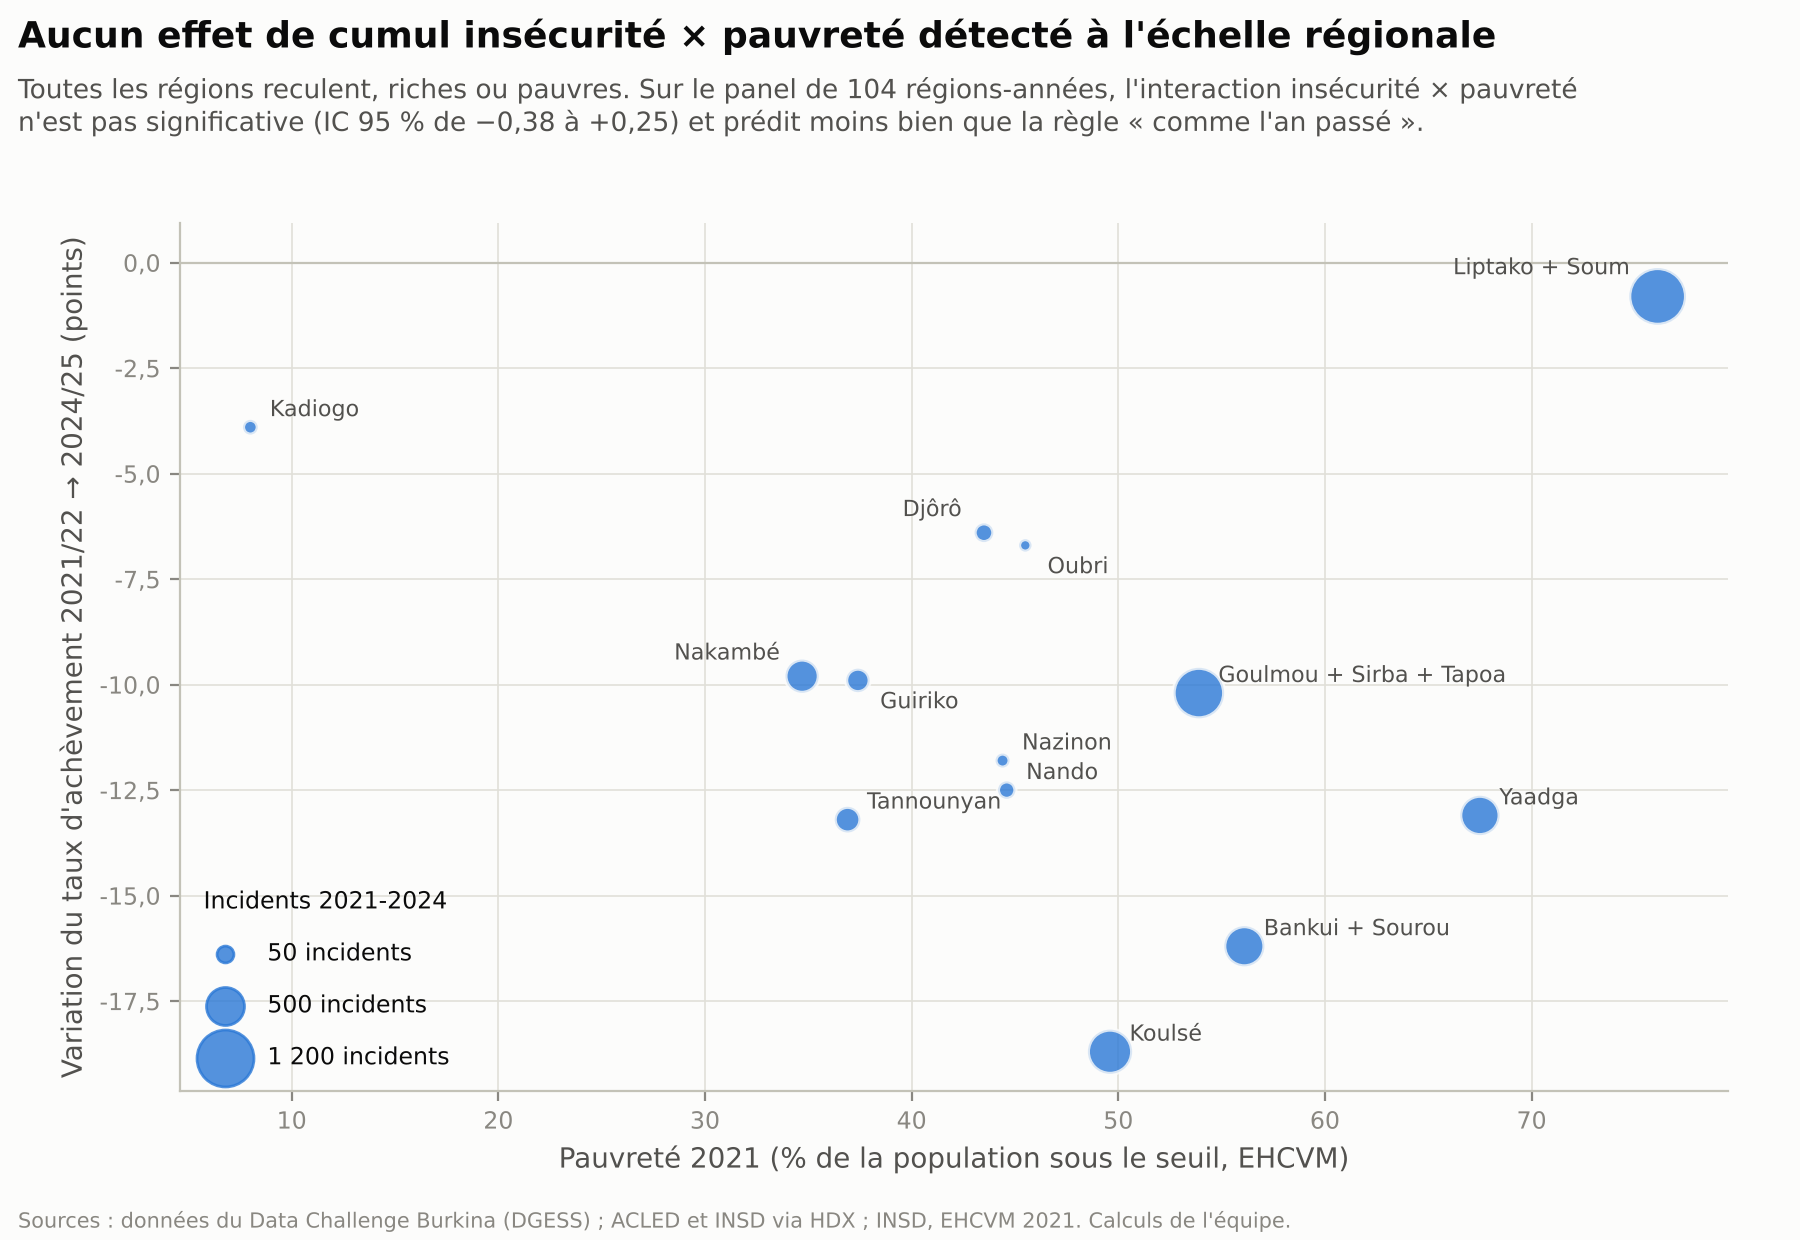

In [12]:
run_figures_prevision = main
t0 = time.time()
sys.argv = ['figures_prevision.py']
run_figures_prevision()
show_figures(t0)

## 3. Apprentissage automatique contre règles simples

`04_analyse/Biiga_04-analyse_D1_scientist_script-apprentissage-automatique_v1.py`

In [13]:
warnings.filterwarnings("ignore")
SEED = 2026
YEARS = [f"{y}-{y + 1}" for y in range(2015, 2025)]
SHORT = {y: y[2:4] + "/" + y[7:] for y in YEARS + ["2025-2026", "2026-2027"]}
LABELS = {
    "TAP_T": "Taux d'achèvement", "dTAP": "Variation du TAP (année écoulée)", "IPS_TAP": "Parité filles/garçons du TAP",
    "TBS_T": "Taux brut de scolarisation", "TBA_T": "Taux brut d'admission", "CEP_T": "Réussite au CEP",
    "dlog_eleves": "Variation des effectifs", "dlog_ecoles": "Variation du nombre d'écoles",
    "dlog_cp1": "Variation des entrées en CP1", "part_public": "Part des écoles publiques",
    "sorties_prev": "Sorties apparentes (année écoulée)", "l_inc": "Incidents (log)",
    "d_l_inc": "Escalade des incidents", "l_morts": "Morts (log)", "pauvrete": "Pauvreté 2021",
}

In [14]:
def key(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return "".join(ch for ch in s.upper() if ch.isalnum())

In [15]:
def build():
    panel = pd.read_csv(chemins.path("panel_region_annee.csv"))
    p = panel[panel.region != "NATIONAL"].copy()
    p["cle"] = p.region.map(key)
    acled = pd.read_csv(chemins.path("acled_region_annee.csv"))
    pov = pd.read_csv(chemins.path("pauvrete_ehcvm_2021_regions.csv"))
    pov["cle"] = pov.region.map(key)
    p = p.merge(acled, on=["cle", "annee"], how="left").merge(
        pov[["cle", "incidence_pauvrete_2021_pct"]], on="cle", how="left").sort_values(["region", "annee"])
    g = p.groupby("region")
    p["dTAP"] = p.TAP_T - g.TAP_T.shift()
    p["dlog_cp1"] = np.log(p.nouveaux_CP1_T / g.nouveaux_CP1_T.shift())
    p["part_public"] = p.ecoles_publiques / p.ecoles
    p["sorties_prev"] = g.sorties_app.shift()
    p["l_inc"] = np.log1p(p.incidents)
    p["d_l_inc"] = p.l_inc - g.l_inc.shift()
    p["l_morts"] = np.log1p(p.morts)
    p["pauvrete"] = p.incidence_pauvrete_2021_pct
    p["y_dTAP"] = g.TAP_T.shift(-1) - p.TAP_T
    p["y_drop"] = (np.log(g.eleves_T.shift(-1) / p.eleves_T) < np.log(0.95)).astype(float)
    p.loc[g.eleves_T.shift(-1).isna(), "y_drop"] = np.nan
    p["rule"] = ((p.incidents >= 1.5 * g.incidents.shift()) & (p.incidents >= 30)).astype(float)
    return p

In [16]:
FEATURES = list(LABELS)

In [17]:
def main():
    pd.set_option("display.width", 200)
    p = build()
    data = p.dropna(subset=FEATURES + ["y_dTAP", "y_drop"]).copy()
    years = sorted(data.annee.unique())
    tests = years[3:]
    print(f"Observations utilisables : {len(data)} (13 régions × {len(years)} années) ; "
          f"années testées : {SHORT[tests[0]]} à {SHORT[tests[-1]]} (prédiction de l'année suivante)")

    reg_models = {
        "Ridge (linéaire régularisé)": lambda: make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
        "Forêt aléatoire": lambda: RandomForestRegressor(n_estimators=500, min_samples_leaf=5, max_features=0.5,
                                                          random_state=SEED),
        "Gradient boosting": lambda: GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                                               subsample=0.8, random_state=SEED),
    }
    rows, imp_rows = [], []
    for ty in tests:
        tr, te = data[data.annee < ty], data[data.annee == ty]
        row = {"annee_predite": SHORT[years[years.index(ty) + 1]] if ty != years[-1] else "24/25",
               "Comme l'an passé": np.abs(te.y_dTAP).mean()}
        for name, mk in reg_models.items():
            mdl = mk().fit(tr[FEATURES], tr.y_dTAP)
            row[name] = np.abs(te.y_dTAP - mdl.predict(te[FEATURES])).mean()
            if name == "Forêt aléatoire":
                pi = permutation_importance(mdl, te[FEATURES], te.y_dTAP, scoring="neg_mean_absolute_error",
                                            n_repeats=30, random_state=SEED)
                imp_rows.append(pd.Series(pi.importances_mean, index=FEATURES))
        rows.append(row)
    reg = pd.DataFrame(rows)
    reg.loc[len(reg)] = ["moyenne"] + list(reg.iloc[:, 1:].mean())
    reg.round(2).to_csv(chemins.path("P11_ml_regression.csv"), index=False)
    print("\n=== 1. Variation du taux d'achèvement l'année suivante : erreur absolue moyenne (points) ===")
    print(reg.round(2).to_string(index=False))
    base = reg.iloc[-1]["Comme l'an passé"]
    for name in reg_models:
        print(f"  {name:30s} gain par rapport à « comme l'an passé » : {(1 - reg.iloc[-1][name] / base) * 100:+.0f} %")
    imp = pd.concat(imp_rows, axis=1).mean(axis=1).sort_values(ascending=False)
    imp = pd.DataFrame({"variable": [LABELS[i] for i in imp.index], "importance_points": imp.values})
    imp.round(3).to_csv(chemins.path("P11_importance.csv"), index=False)
    print("\nImportance des variables (forêt aléatoire, permutation sur les années testées ; "
          "points d'erreur gagnés quand la variable est connue) :")
    print(imp.head(8).round(3).to_string(index=False))

    clf_models = {
        "Logistique, violence seule": (["l_inc", "d_l_inc"],
                                       lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0))),
        "Logistique, toutes variables": (FEATURES,
                                         lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.3, max_iter=2000))),
        "Forêt aléatoire": (FEATURES, lambda: RandomForestClassifier(n_estimators=500, min_samples_leaf=5,
                                                                    max_features=0.5, random_state=SEED)),
    }
    preds = {n: [] for n in clf_models}
    truth, rule = [], []
    for ty in tests:
        tr, te = data[data.annee < ty], data[data.annee == ty]
        truth += list(te.y_drop)
        rule += list(te.rule)
        for name, (cols, mk) in clf_models.items():
            if tr.y_drop.nunique() < 2:
                preds[name] += [tr.y_drop.mean()] * len(te)
                continue
            mdl = mk().fit(tr[cols], tr.y_drop)
            preds[name] += list(mdl.predict_proba(te[cols])[:, 1])
    truth, rule = np.array(truth), np.array(rule)
    out = []
    pos = truth.sum()
    out.append({"modele": "Règle d'escalade (D7)", "AUC": roc_auc_score(truth, rule), "Brier": np.nan,
                "alertes": int(rule.sum()), "baisses_annoncees": int((rule * truth).sum()),
                "precision_%": (rule * truth).sum() / max(rule.sum(), 1) * 100, "rappel_%": (rule * truth).sum() / pos * 100})
    for name, pr in preds.items():
        pr = np.array(pr)
        flag = pr >= 0.5
        out.append({"modele": name, "AUC": roc_auc_score(truth, pr), "Brier": brier_score_loss(truth, pr),
                    "alertes": int(flag.sum()), "baisses_annoncees": int((flag * truth).sum()),
                    "precision_%": (flag * truth).sum() / max(flag.sum(), 1) * 100, "rappel_%": (flag * truth).sum() / pos * 100})
    out.append({"modele": "Aucun modèle (taux de base)", "AUC": 0.5,
                "Brier": brier_score_loss(truth, np.full(len(truth), truth.mean())), "alertes": 0, "baisses_annoncees": 0,
                "precision_%": np.nan, "rappel_%": 0})
    clf = pd.DataFrame(out)
    clf.round(3).to_csv(chemins.path("P11_ml_classification.csv"), index=False)
    print(f"\n=== 2. Baisse des effectifs de plus de 5 % l'année suivante ({len(truth)} prédictions hors échantillon, "
          f"{int(pos)} baisses réelles) ===")
    print(clf.round(3).to_string(index=False))
    print("AUC : 0,5 = hasard, 1 = parfait. Brier : plus bas = probabilités plus justes. Seuil d'alerte des modèles : 50 %.")

    cols, mk = clf_models["Logistique, violence seule"]
    final = mk().fit(data[cols], data.y_drop)
    acled = pd.read_csv(chemins.path("acled_region_annee.csv")).sort_values(["cle", "annee"])
    acled["l_inc"] = np.log1p(acled.incidents)
    acled["d_l_inc"] = acled.l_inc - acled.groupby("cle").l_inc.shift()
    names = p.drop_duplicates("cle").set_index("cle")
    n25 = pd.read_csv(chemins.path("panel_region_annee_2025.csv")).drop_duplicates("region").set_index("region").region_2025
    res = []
    for yr, label in [("2024-2025", "rentrée 2025/26"), ("2025-2026", "rentrée 2026/27")]:
        cur = acled[acled.annee == yr].set_index("cle")
        cur = cur[cur.index.isin(names.index)]
        prob = final.predict_proba(cur[cols])[:, 1]
        for c, pr, inc in zip(cur.index, prob, cur.incidents):
            res.append({"region_2025": n25[names.loc[c, "region"]], "periode": label, "incidents": int(inc),
                        "probabilite_baisse_%": round(pr * 100)})
    res = pd.DataFrame(res).pivot_table(index="region_2025", columns="periode", values="probabilite_baisse_%")
    res = res.sort_values("rentrée 2026/27", ascending=False)
    res.to_csv(chemins.path("P11_probabilites_alerte.csv"))
    print("\nProbabilité d'une baisse des effectifs de plus de 5 % (logistique, violence seule, entraînée sur 2015-2025) :")
    print(res.to_string())

In [18]:
run_machine_learning = main
t0 = time.time()
sys.argv = ['machine_learning.py']
run_machine_learning()
show_figures(t0)

Observations utilisables : 104 (13 régions × 8 années) ; années testées : 19/20 à 23/24 (prédiction de l'année suivante)



=== 1. Variation du taux d'achèvement l'année suivante : erreur absolue moyenne (points) ===
annee_predite  Comme l'an passé  Ridge (linéaire régularisé)  Forêt aléatoire  Gradient boosting
        20/21              3.65                         3.69             3.80               4.02
        21/22              4.50                         4.23             4.29               4.37
        22/23              7.24                         6.91             6.63               6.56
        23/24              2.42                         3.47             4.36               5.30
        24/25              3.36                         4.58             3.64               3.72
      moyenne              4.23                         4.58             4.54               4.79
  Ridge (linéaire régularisé)    gain par rapport à « comme l'an passé » : -8 %
  Forêt aléatoire                gain par rapport à « comme l'an passé » : -7 %
  Gradient boosting              gain par rapport à « comme l'an pa


=== 2. Baisse des effectifs de plus de 5 % l'année suivante (65 prédictions hors échantillon, 14 baisses réelles) ===
                      modele   AUC  Brier  alertes  baisses_annoncees  precision_%  rappel_%
       Règle d'escalade (D7) 0.681    NaN       14                  7       50.000    50.000
  Logistique, violence seule 0.829  0.166       23                  9       39.130    64.286
Logistique, toutes variables 0.751  0.204       19                  8       42.105    57.143
             Forêt aléatoire 0.777  0.179       20                  9       45.000    64.286
 Aucun modèle (taux de base) 0.500  0.169        0                  0          NaN     0.000
AUC : 0,5 = hasard, 1 = parfait. Brier : plus bas = probabilités plus justes. Seuil d'alerte des modèles : 50 %.

Probabilité d'une baisse des effectifs de plus de 5 % (logistique, violence seule, entraînée sur 2015-2025) :
periode                  rentrée 2025/26  rentrée 2026/27
region_2025                              

## 4. Figures de l'apprentissage automatique

`04_analyse/Biiga_04-analyse_D1_scientist_script-figures-apprentissage_v1.py`

In [19]:
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
TIERS = [(40, "Risque élevé (≥ 40 %)", "#104281"), (15, "Risque moyen (15-39 %)", "#3987e5"),
         (0, "Risque faible (< 15 %)", "#b7d3f6")]
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10, "text.color": INK, "axes.edgecolor": AXIS,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

In [20]:
def header(fig, main, sub):
    fig.text(0.01, 0.985, main, fontsize=13, fontweight="bold", color=INK, va="top")
    fig.text(0.01, 0.94, sub, fontsize=9.5, color=INK2, va="top")
    fig.text(0.01, 0.01, "Sources : données du Data Challenge Burkina (DGESS) ; ACLED (HDX) ; INSD, EHCVM 2021. "
             "Calculs de l'équipe.", fontsize=7.5, color=MUTED)

In [21]:
def main():
    reg = pd.read_csv(chemins.path("P11_ml_regression.csv"))
    reg = reg[reg.annee_predite != "moyenne"]
    cols = ["Comme l'an passé", "Ridge (linéaire régularisé)", "Forêt aléatoire", "Gradient boosting"]
    short = ["Comme l'an passé", "Ridge", "Forêt aléatoire", "Gradient boosting"]
    fig, ax = plt.subplots(figsize=(9, 5.2))
    fig.subplots_adjust(top=0.80, bottom=0.13, left=0.08, right=0.80)
    for c, col in zip(cols, SERIES):
        lw = 2.6 if c == "Comme l'an passé" else 1.8
        ax.plot(reg.annee_predite, reg[c], color=col, marker="o", markersize=5, linewidth=lw, label=c)
    ends = sorted(((reg[c].iloc[-1], s) for c, s in zip(cols, short)))
    placed = []
    for v, s in ends:
        y = max(v, placed[-1] + 0.28) if placed else v
        placed.append(y)
        ax.annotate(s, (len(reg) - 1, v), xytext=(len(reg) - 1 + 0.08, y), textcoords="data", va="center",
                    fontsize=8.5, color=INK2, annotation_clip=False)
    ax.set_ylim(0, None)
    ax.set_ylabel("Erreur moyenne sur la variation du TAP (points)")
    ax.set_xlabel("Année prédite (modèles entraînés sur les années précédentes seulement)")
    ax.legend(loc="upper left", fontsize=8.5)
    header(fig, "L'apprentissage automatique ne bat pas « comme l'an passé »",
           "Erreur moyenne : 4,23 points pour la règle simple, contre 4,54 à 4,79 pour les trois modèles. Ils font un peu mieux\n"
           "l'année du choc (22/23), nettement moins bien l'année des réouvertures (23/24).")
    fig.savefig(chemins.path("11_ml_regression.png"), dpi=200)
    plt.close(fig)

    pr = pd.read_csv(chemins.path("P11_probabilites_alerte.csv")).sort_values("rentrée 2026/27")
    fig, ax = plt.subplots(figsize=(9, 5.6))
    fig.subplots_adjust(top=0.80, bottom=0.12, left=0.24, right=0.95)
    colors = [next(c for t, _, c in TIERS if v >= t) for v in pr["rentrée 2026/27"]]
    ax.barh(pr.region_2025, pr["rentrée 2026/27"], color=colors, height=0.62)
    ax.grid(axis="y", visible=False)
    ax.set_xlim(0, 100)
    for i, v in enumerate(pr["rentrée 2026/27"]):
        if v >= 15:
            ax.annotate(f"{v:.0f} %", (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=8.5,
                        color=INK2)
    ax.legend(handles=[Patch(color=c, label=l) for _, l, c in TIERS], loc="lower right", fontsize=8.5)
    ax.set_xlabel("Probabilité d'une baisse des effectifs de plus de 5 % en 2026/27")
    header(fig, "Où le risque monte pour 2026/27",
           "Régression logistique sur la violence d'oct. 2025 à sept. 2026. Elle classe bien les régions (AUC 0,83 hors échantillon),\n"
           "mais ses probabilités sont approximatives : on lit des niveaux de risque, pas des pourcentages exacts.")
    fig.savefig(chemins.path("12_risque_2026_27.png"), dpi=200)
    plt.close(fig)
    print("2 figures écrites")

2 figures écrites
04_analyse/figures/Biiga_04-analyse_D1_scientist_figure-11-ml-regression_v1.png


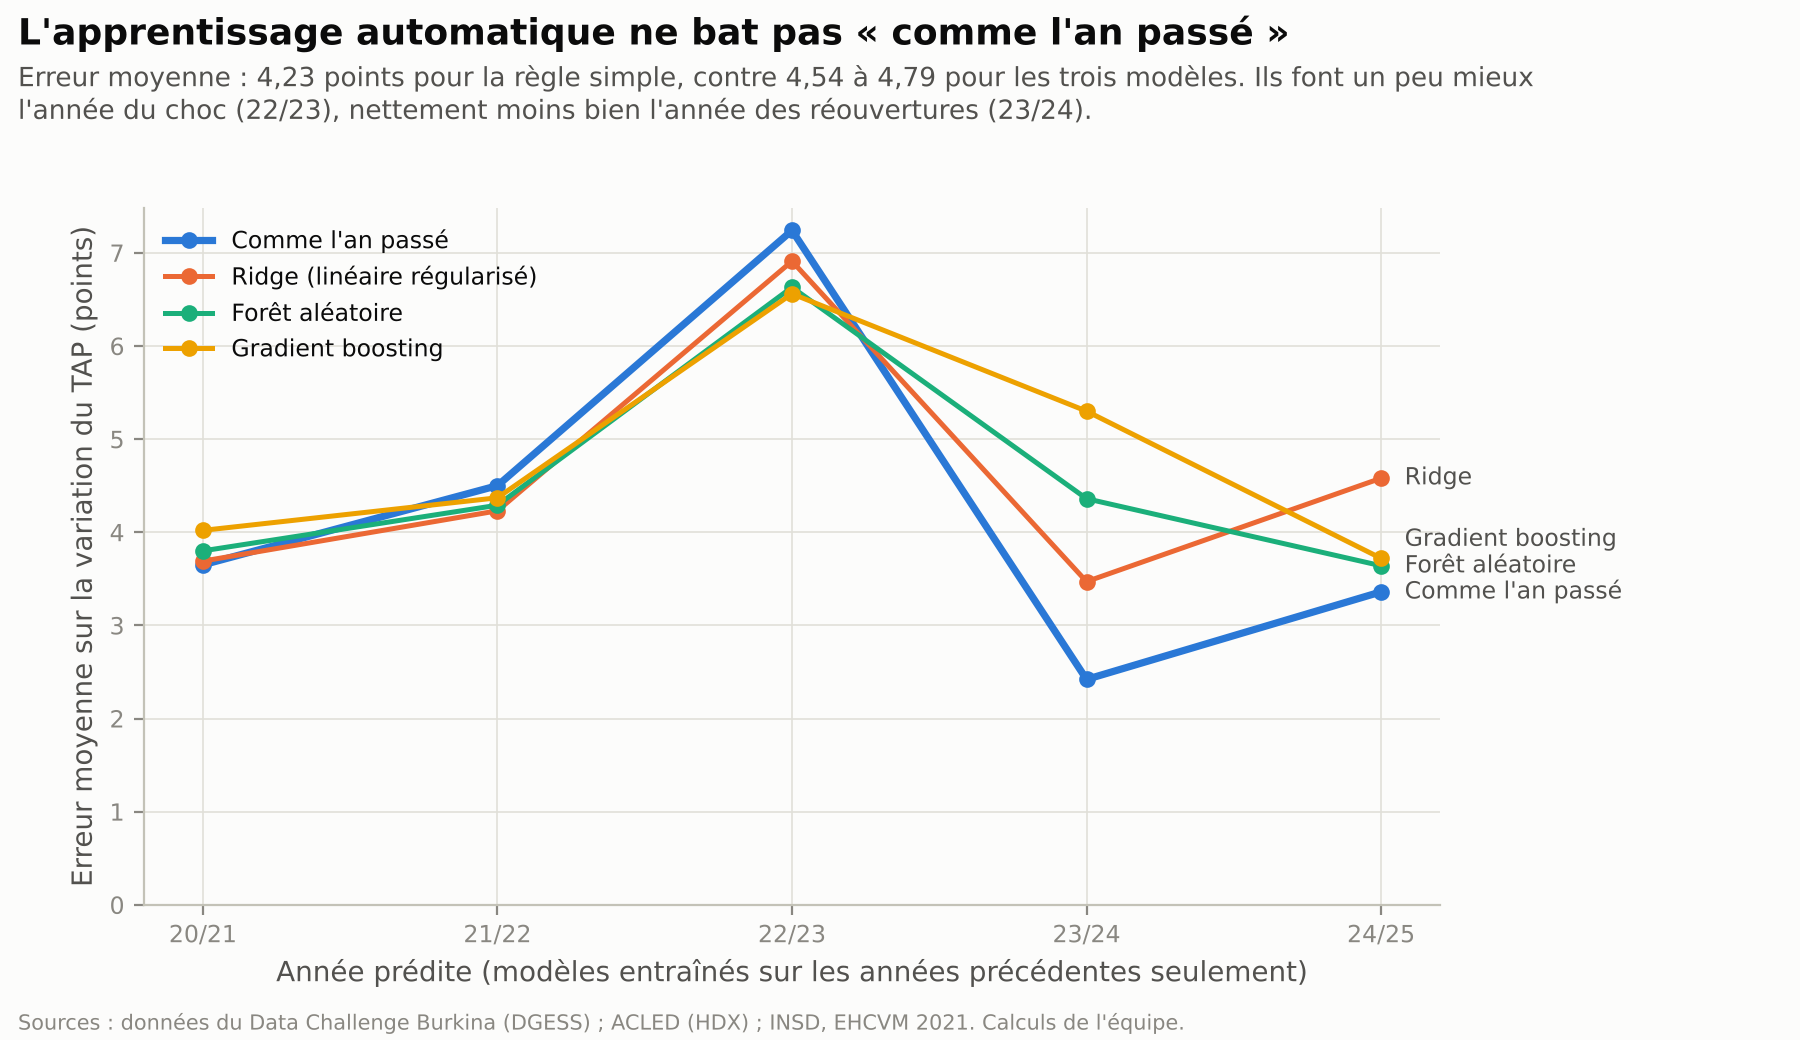

04_analyse/figures/Biiga_04-analyse_D1_scientist_figure-12-risque-2026-27_v1.png


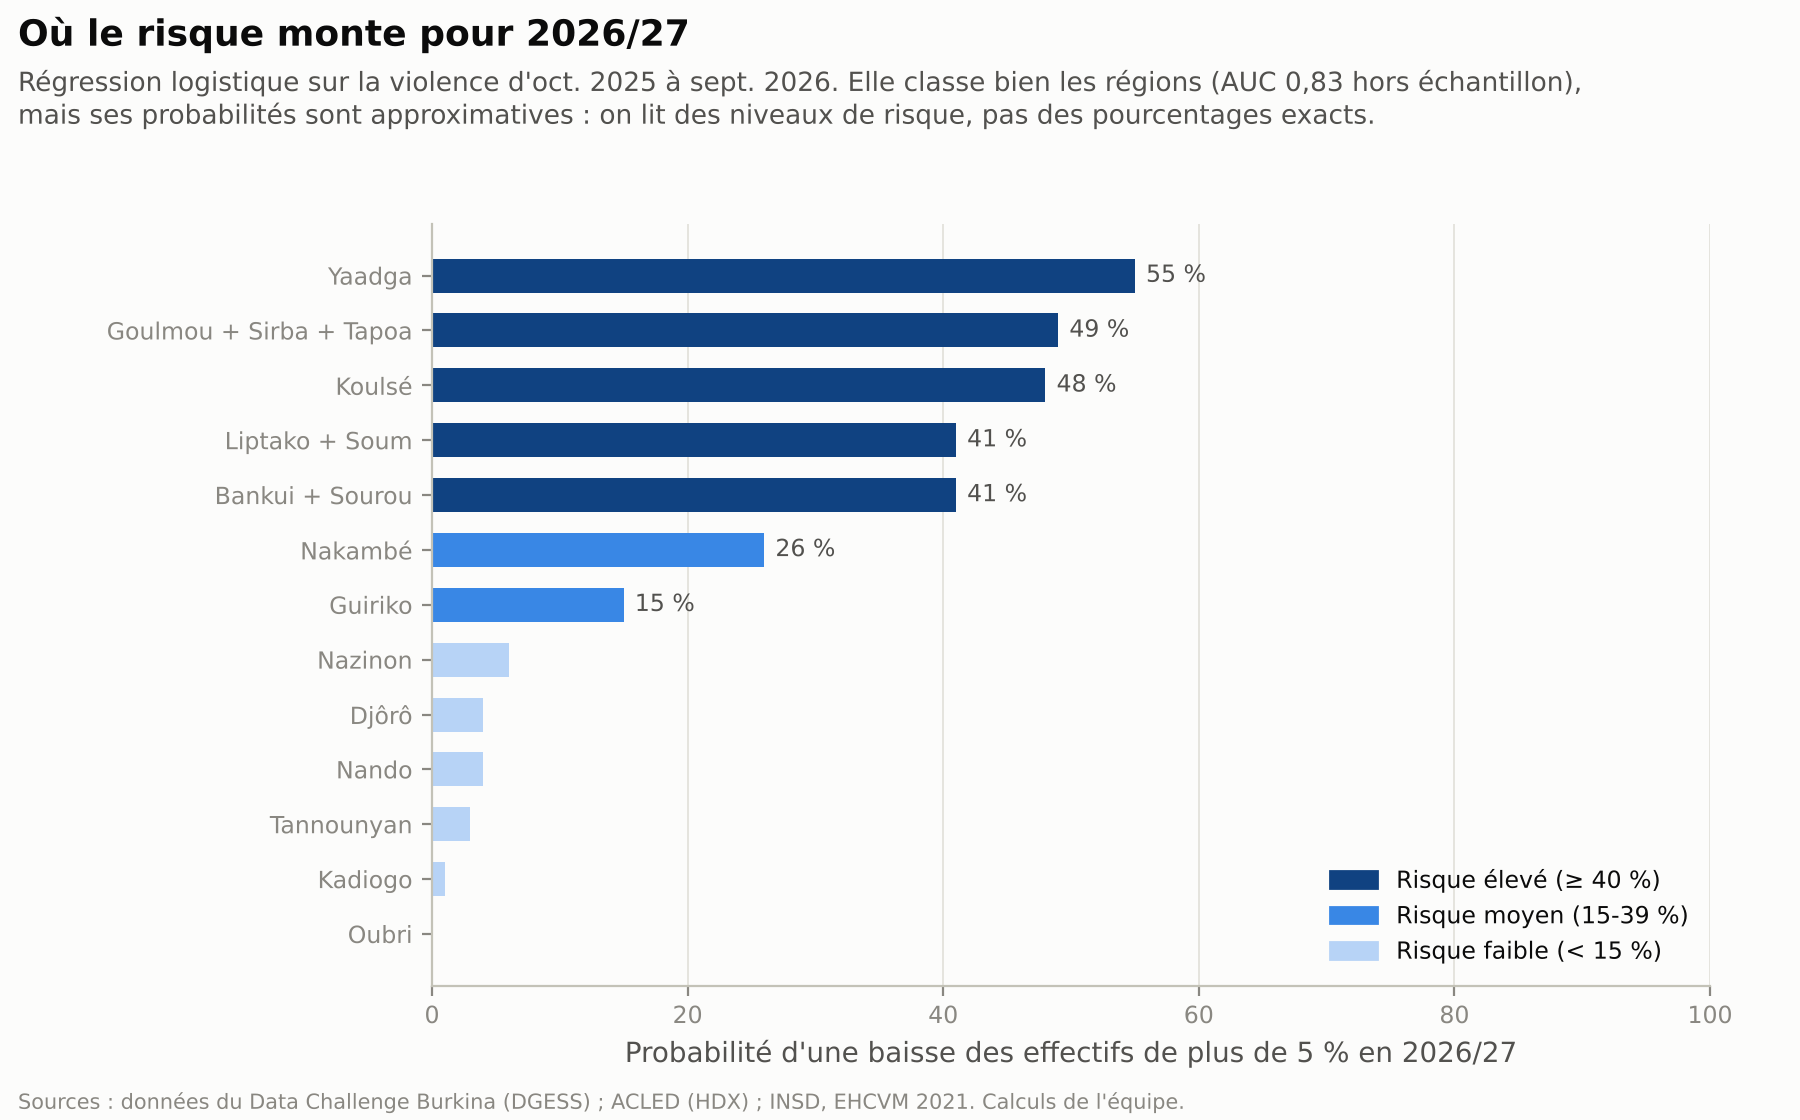

In [22]:
run_figures_ml = main
t0 = time.time()
sys.argv = ['figures_ml.py']
run_figures_ml()
show_figures(t0)

## 5. Écoles ouvertes et filière des cohortes

`04_analyse/Biiga_04-analyse_D1_scientist_script-approches-prevision_v1.py`

In [23]:
YEARS = [f"{y}-{y + 1}" for y in range(2015, 2025)]
SHORT = {y: y[2:4] + "/" + y[7:] for y in YEARS}

In [24]:
def main():
    pd.set_option("display.width", 200)
    p = pd.read_csv(chemins.path("panel_region_annee.csv"))
    reg = p[p.region != "NATIONAL"].sort_values(["region", "annee"]).copy()
    g = reg.groupby("region")
    reg["dTAP"] = reg.TAP_T - g.TAP_T.shift()
    d = reg.dropna(subset=["dlog_eleves", "dlog_ecoles", "dTAP"])

    print("=== A. Prévoir l'année en cours dès qu'on connaît les écoles ouvertes à la rentrée ===")
    rows = []
    for ty in sorted(d.annee.unique())[2:]:
        tr, te = d[d.annee < ty], d[d.annee == ty]
        b1, b0 = np.polyfit(tr.dlog_ecoles, tr.dlog_eleves, 1)
        c1, c0 = np.polyfit(tr.dlog_ecoles, tr.dTAP, 1)
        rows.append({
            "annee": SHORT[ty],
            "effectifs_persistance_%": np.abs(te.dlog_eleves).mean() * 100,
            "effectifs_ecoles_%": np.abs(te.dlog_eleves - (b0 + b1 * te.dlog_ecoles)).mean() * 100,
            "TAP_persistance_pts": np.abs(te.dTAP).mean(),
            "TAP_ecoles_pts": np.abs(te.dTAP - (c0 + c1 * te.dlog_ecoles)).mean(),
        })
    a = pd.DataFrame(rows)
    a.loc[len(a)] = ["moyenne"] + list(a.iloc[:, 1:].mean())
    print(a.round(2).to_string(index=False))
    m = a.iloc[-1]
    print(f"Effectifs : erreur {m['effectifs_ecoles_%']:.1f} % contre {m['effectifs_persistance_%']:.1f} % "
          f"(gain {(1 - m['effectifs_ecoles_%'] / m['effectifs_persistance_%']) * 100:.0f} %) ; "
          f"TAP : {m['TAP_ecoles_pts']:.2f} contre {m['TAP_persistance_pts']:.2f} points "
          f"(gain {(1 - m['TAP_ecoles_pts'] / m['TAP_persistance_pts']) * 100:.0f} %)")

    print("\n=== B. Filière des cohortes (national) : le CM2 de demain est dans le CM1 d'aujourd'hui ===")
    t = pd.read_csv(chemins.path("presco_tidy.csv"))
    e4 = t[(t.table == "E4") & t.statut.isin(["Public", "Prive"]) & (t.sexe == "T")]
    gr = e4.groupby(["niveau", "annee"]).valeur.sum().unstack("annee")[YEARS]
    nat = p[p.region == "NATIONAL"].set_index("annee").loc[YEARS]
    rows = []
    for i in range(2, 10):
        y0, y1, ym = YEARS[i - 1], YEARS[i], YEARS[i - 2]
        rate = gr.loc["CM2", y0] / gr.loc["CM1", ym]
        cm2_hat = gr.loc["CM1", y0] * rate
        tap_hat = nat.TAP_T[y0] * cm2_hat / gr.loc["CM2", y0]
        rows.append({"annee": SHORT[y1], "CM2_reel": gr.loc["CM2", y1], "CM2_filiere": round(cm2_hat),
                     "err_CM2_filiere_%": abs(cm2_hat / gr.loc["CM2", y1] - 1) * 100,
                     "err_CM2_persistance_%": abs(gr.loc["CM2", y0] / gr.loc["CM2", y1] - 1) * 100,
                     "TAP_reel": nat.TAP_T[y1], "TAP_filiere": tap_hat,
                     "err_TAP_filiere": abs(tap_hat - nat.TAP_T[y1]), "err_TAP_persistance": abs(nat.TAP_T[y0] - nat.TAP_T[y1])})
    b = pd.DataFrame(rows)
    print(b.round(1).to_string(index=False))
    print("Moyennes :", b[["err_CM2_filiere_%", "err_CM2_persistance_%", "err_TAP_filiere", "err_TAP_persistance"]]
          .mean().round(2).to_dict())
    rows = []
    for i in range(3, 10):
        y0, y2 = YEARS[i - 2], YEARS[i]
        r1 = gr.loc["CM1", y0] / gr.loc["CE2", YEARS[i - 3]]
        r2 = gr.loc["CM2", y0] / gr.loc["CM1", YEARS[i - 3]]
        cm2_hat = gr.loc["CE2", y0] * r1 * r2
        rows.append({"annee": SHORT[y2], "err_filiere_2ans_%": abs(cm2_hat / gr.loc["CM2", y2] - 1) * 100,
                     "err_persistance_2ans_%": abs(gr.loc["CM2", y0] / gr.loc["CM2", y2] - 1) * 100})
    c = pd.DataFrame(rows)
    print("\nDeux ans à l'avance (CM2), erreur moyenne :", c.iloc[:, 1:].mean().round(1).to_dict())
    rate = gr.loc["CM2", "2024-2025"] / gr.loc["CM1", "2023-2024"]
    r1 = gr.loc["CM1", "2024-2025"] / gr.loc["CE2", "2023-2024"]
    print(f"\nProjection : CM2 2025/26 ≈ {gr.loc['CM1', '2024-2025'] * rate:,.0f} (CM1 2024/25 = "
          f"{gr.loc['CM1', '2024-2025']:,.0f}, passage {rate:.1%}) ; CM2 2024/25 = {gr.loc['CM2', '2024-2025']:,.0f}")
    print(f"             CM2 2026/27 ≈ {gr.loc['CE2', '2024-2025'] * r1 * rate:,.0f} (à partir du CE2 2024/25)")
    print("Entrées en CP1 :", {SHORT[y]: int(gr.loc['CP1', y]) for y in YEARS[-4:]})
    a.round(2).to_csv(chemins.path("P12_nowcast_ecoles.csv"), index=False)
    b.round(2).to_csv(chemins.path("P12_filiere_un_an.csv"), index=False)
    robustness(gr, nat)

In [25]:
def robustness(gr, nat):
    print("\n=== C. Solidité de la projection du CM2, et ce qu'annoncent les grandes cohortes de CP1 ===")
    transition = pd.Series({YEARS[i]: gr.loc["CM2", YEARS[i]] / gr.loc["CM1", YEARS[i - 1]] for i in range(1, 10)})
    print("Passage du CM1 au CM2 :", {SHORT[y]: f"{v:.1%}" for y, v in transition.items()})
    rows = []
    for i in range(3, 10):
        y0, y1 = YEARS[i - 1], YEARS[i]
        known = transition.loc[:y0]
        lo, hi = gr.loc["CM1", y0] * known.min(), gr.loc["CM1", y0] * known.max()
        mid = gr.loc["CM1", y0] * known.iloc[-1]
        real = gr.loc["CM2", y1]
        rows.append({"annee": SHORT[y1], "bas": round(lo), "central": round(mid), "haut": round(hi), "reel": real,
                     "dans_fourchette": lo <= real <= hi,
                     "sens_annonce": "hausse" if mid > gr.loc["CM2", y0] else "baisse",
                     "sens_reel": "hausse" if real > gr.loc["CM2", y0] else "baisse"})
    r = pd.DataFrame(rows)
    print(r.to_string(index=False))
    print(f"Fourchette tenue {r.dans_fourchette.sum()} fois sur {len(r)} ; sens juste {(r.sens_annonce == r.sens_reel).sum()} "
          f"fois sur {len(r)}")
    cm1 = gr.loc["CM1", "2024-2025"]
    proj = {"bas": cm1 * transition.min(), "central": cm1 * transition.iloc[-1], "haut": cm1 * transition.max()}
    print(f"CM2 2025/26 : {proj['central']:,.0f} [{proj['bas']:,.0f} ; {proj['haut']:,.0f}] contre "
          f"{gr.loc['CM2', '2024-2025']:,.0f} en 2024/25 ; même le pire passage observé ({transition.min():.1%}, année du choc) "
          f"donne {proj['bas'] / gr.loc['CM2', '2024-2025'] - 1:+.1%}")
    den = gr.loc["CM2"] / (nat.TAP_T / 100)
    print("Variation du dénominateur implicite du TAP (CM2 / TAP) :",
          {SHORT[y]: f"{v:+.1%}" for y, v in (den / den.shift() - 1).dropna().items()})
    surv = pd.Series({YEARS[i]: gr.loc["CM2", YEARS[i]] / gr.loc["CP1", YEARS[i - 5]] for i in range(5, 10)})
    print("Survie apparente CP1 -> CM2 (5 ans plus tard) :", {SHORT[y]: f"{v:.1%}" for y, v in surv.items()})
    print("National, taux brut d'admission :", {SHORT[y]: round(v) for y, v in nat.TBA_T.items()})
    long_rows = []
    for y in ["2022-2023", "2023-2024", "2024-2025"]:
        arrival = f"{int(y[:4]) + 5}-{int(y[:4]) + 6}"
        cp1 = gr.loc["CP1", y]
        long_rows.append({"cohorte_CP1": SHORT[y], "en_CM2": arrival[2:4] + "/" + arrival[7:], "CP1": int(cp1),
                          "CM2_survie_recente": round(cp1 * surv.iloc[-1]), "CM2_survie_max": round(cp1 * surv.max())})
    lr = pd.DataFrame(long_rows)
    print("Scénario, pas une prévision (survie récente / meilleure survie observée) :")
    print(lr.to_string(index=False))
    out = pd.DataFrame({"annee": [SHORT[y] for y in YEARS], "CM2": gr.loc["CM2"].values, "CP1": gr.loc["CP1"].values})
    out.to_csv(chemins.path("P12_cohortes_national.csv"), index=False)
    pd.DataFrame([{"annee": "25/26", **{k: round(v) for k, v in proj.items()}}]).to_csv(
        chemins.path("P12_projection_CM2.csv"), index=False)
    r.to_csv(chemins.path("P12_filiere_fourchette.csv"), index=False)
    lr.to_csv(chemins.path("P12_scenario_cohortes_CP1.csv"), index=False)

In [26]:
run_approches_prevision = main
t0 = time.time()
sys.argv = ['approches_prevision.py']
run_approches_prevision()
show_figures(t0)

=== A. Prévoir l'année en cours dès qu'on connaît les écoles ouvertes à la rentrée ===
  annee  effectifs_persistance_%  effectifs_ecoles_%  TAP_persistance_pts  TAP_ecoles_pts
  18/19                     7.89                5.13                 2.97            4.73
  19/20                     5.48                2.68                 3.52            3.26
  20/21                     4.54                5.67                 3.65            2.76
  21/22                     7.15                3.88                 4.50            4.04
  22/23                    15.43                5.55                 7.24            5.60
  23/24                    11.34                2.97                 2.42            3.63
  24/25                     8.40                3.56                 3.36            3.78
moyenne                     8.60                4.21                 3.95            3.97
Effectifs : erreur 4.2 % contre 8.6 % (gain 51 %) ; TAP : 3.97 contre 3.95 points (gain -1 %)

=== B. F

## 6. Où, combien, matrice de priorité 2026/27

`04_analyse/Biiga_04-analyse_D1_scientist_script-solution-prevision_v1.py`

In [27]:
YEARS = [f"{y}-{y + 1}" for y in range(2015, 2025)]
SHORT = {f"{y}-{y + 1}": f"{str(y)[2:]}/{str(y + 1)[2:]}" for y in range(2014, 2028)}

In [28]:
def key(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return "".join(ch for ch in s.upper() if ch.isalnum())

In [29]:
def ols(x, y):
    X = np.column_stack([np.ones(len(x[0]))] + [np.asarray(c, float) for c in x])
    return np.linalg.lstsq(X, np.asarray(y, float), rcond=None)[0]

In [30]:
def pred(beta, x):
    X = np.column_stack([np.ones(len(x[0]))] + [np.asarray(c, float) for c in x])
    return X @ beta

In [31]:
def build():
    p = pd.read_csv(chemins.path("panel_region_annee.csv"))
    p = p[p.region != "NATIONAL"].copy()
    p["cle"] = p.region.map(key)
    acled = pd.read_csv(chemins.path("acled_region_annee.csv"))
    p = p.merge(acled, on=["cle", "annee"], how="left").sort_values(["region", "annee"])
    g = p.groupby("region")
    p["l_inc"] = np.log1p(p.incidents)
    p["d_l_inc"] = p.l_inc - g.l_inc.shift()
    p["dTAP"] = p.TAP_T - g.TAP_T.shift()
    p["sorties_prev"] = g.sorties_app.shift()
    p["y_eleves"] = g.dlog_eleves.shift(-1)
    p["y_ecoles"] = g.dlog_ecoles.shift(-1)
    p["y_dTAP"] = g.TAP_T.shift(-1) - p.TAP_T
    return p

In [32]:
def where(p):
    print("=== 1. OÙ sera le risque l'an prochain ? Stabilité du classement des régions ===")
    rows = []
    for i in range(1, 10):
        a = p[p.annee == YEARS[i - 1]].set_index("region")
        b = p[p.annee == YEARS[i]].set_index("region")
        low_a = set(a.TAP_T.nsmallest(4).index)
        low_b = set(b.TAP_T.nsmallest(4).index)
        row = {"annee": SHORT[YEARS[i]], "rang_TAP": spearmanr(a.TAP_T, b.TAP_T.loc[a.index])[0],
               "4_plus_bas_retrouves": len(low_a & low_b)}
        if i >= 2:
            sa, sb = a.sorties_app.dropna(), b.sorties_app.dropna()
            common = sa.index.intersection(sb.index)
            if len(common) > 5:
                row["rang_sorties"] = spearmanr(sa.loc[common], sb.loc[common])[0]
        rows.append(row)
    r = pd.DataFrame(rows)
    print(r.round(2).to_string(index=False))
    print(f"Moyennes : rang du TAP {r.rang_TAP.mean():.2f} ; 4 régions les plus basses retrouvées "
          f"{r['4_plus_bas_retrouves'].mean():.1f} sur 4 ; rang des sorties {r.rang_sorties.mean():.2f}")
    r.round(3).to_csv(chemins.path("P13_stabilite_classement.csv"), index=False)

In [33]:
def how_many(p):
    print("\n=== 2. COMBIEN d'élèves l'an prochain ? Erreur absolue moyenne sur la variation (%) ===")
    d = p.dropna(subset=["y_eleves", "y_ecoles", "dlog_eleves", "dlog_ecoles", "l_inc", "d_l_inc"])
    years = sorted(d.annee.unique())
    rows, preds = [], []
    for ty in years[3:]:
        tr, te = d[d.annee < ty], d[d.annee == ty]
        out = {"B0 comme l'an passé": np.zeros(len(te)), "B1 même variation": te.dlog_eleves.values}
        b = ols([tr.l_inc, tr.d_l_inc], tr.y_eleves)
        out["E1 violence"] = pred(b, [te.l_inc, te.d_l_inc])
        b = ols([tr.l_inc, tr.d_l_inc, tr.dlog_eleves], tr.y_eleves)
        out["E2 violence + rebond"] = pred(b, [te.l_inc, te.d_l_inc, te.dlog_eleves])
        bs = ols([tr.l_inc, tr.d_l_inc, tr.dlog_ecoles], tr.y_ecoles)
        bp = ols([tr.y_ecoles], tr.y_eleves)
        out["E3 violence → écoles → élèves"] = pred(bp, [pred(bs, [te.l_inc, te.d_l_inc, te.dlog_ecoles])])
        row = {"annee_predite": SHORT[years[years.index(ty) + 1]] if ty != years[-1] else "24/25"}
        row.update({k: np.abs(te.y_eleves.values - v).mean() * 100 for k, v in out.items()})
        rows.append(row)
        for k, v in out.items():
            preds.append(pd.DataFrame({"annee": ty, "region": te.region.values, "modele": k, "prevu": v,
                                       "reel": te.y_eleves.values}))
    r = pd.DataFrame(rows)
    r.loc[len(r)] = ["moyenne"] + list(r.iloc[:, 1:].mean())
    print(r.round(2).to_string(index=False))
    base = r.iloc[-1]["B0 comme l'an passé"]
    for c in r.columns[2:]:
        print(f"  {c:32s} gain par rapport à « comme l'an passé » : {(1 - r.iloc[-1][c] / base) * 100:+.0f} %")
    r.round(2).to_csv(chemins.path("P13_effectifs_modeles.csv"), index=False)
    allp = pd.concat(preds)
    big = allp[np.abs(allp.reel) > np.log(1.05)]
    print(f"\nSens de la variation quand elle dépasse 5 % ({big.region.nunique()} régions, "
          f"{len(big) // allp.modele.nunique()} cas) :")
    for k, gk in big.groupby("modele", sort=False):
        if k.startswith("B0"):
            continue
        print(f"  {k:32s} sens juste {(np.sign(gk.prevu) == np.sign(gk.reel)).mean() * 100:.0f} %")
    allp.to_csv(chemins.path("P13_effectifs_predictions.csv"), index=False)
    return d

In [34]:
def how_much(p):
    print("\n=== 3. DE COMBIEN bougera le taux d'achèvement ? Erreur absolue moyenne (points) ===")
    d = p.dropna(subset=["y_dTAP", "dTAP", "d_l_inc"])
    years = sorted(d.annee.unique())
    rows = []
    for ty in years[3:]:
        tr, te = d[d.annee < ty], d[d.annee == ty]
        row = {"annee_predite": SHORT[years[years.index(ty) + 1]] if ty != years[-1] else "24/25",
               "B0 comme l'an passé": np.abs(te.y_dTAP).mean()}
        b = ols([tr.dTAP], tr.y_dTAP)
        row["T1 retour partiel"] = np.abs(te.y_dTAP - pred(b, [te.dTAP])).mean()
        b = ols([tr.dTAP, tr.d_l_inc], tr.y_dTAP)
        row["T2 retour + escalade"] = np.abs(te.y_dTAP - pred(b, [te.dTAP, te.d_l_inc])).mean()
        rows.append(row)
    r = pd.DataFrame(rows)
    r.loc[len(r)] = ["moyenne"] + list(r.iloc[:, 1:].mean())
    print(r.round(2).to_string(index=False))
    r.round(2).to_csv(chemins.path("P13_TAP_modeles.csv"), index=False)

In [35]:
def priority(tap, tap_nat, prob):
    if tap < tap_nat and prob >= 0.40:
        return 1
    if tap < tap_nat or prob >= 0.15:
        return 2
    return 3

In [36]:
def backtest_matrix(p):

    print("\n=== 4. La matrice de priorité, rejouée sur le passé (année t -> ce qui arrive en t+1) ===")
    nat = pd.read_csv(chemins.path("panel_region_annee.csv")).query("region == 'NATIONAL'").set_index("annee").TAP_T
    d = p.dropna(subset=["l_inc", "d_l_inc", "y_eleves"]).copy()
    d["y_drop"] = (d.y_eleves < np.log(0.95)).astype(int)
    d["lost"] = np.maximum(0, d.eleves_T * (1 - np.exp(d.y_eleves)))
    years = sorted(d.annee.unique())
    rows = []
    for ty in years[3:]:
        tr, te = d[d.annee < ty], d[d.annee == ty].copy()
        if tr.y_drop.nunique() < 2:
            continue
        mdl = make_pipeline(StandardScaler(), LogisticRegression(C=1.0)).fit(tr[["l_inc", "d_l_inc"]], tr.y_drop)
        te["prob"] = mdl.predict_proba(te[["l_inc", "d_l_inc"]])[:, 1]
        te["prio"] = [priority(t, nat[ty], pr) for t, pr in zip(te.TAP_T, te.prob)]
        p1 = te.prio == 1
        rows.append({"annee_t": SHORT[ty], "regions_P1": int(p1.sum()), "baisses_t+1": int(te.y_drop.sum()),
                     "baisses_dans_P1": int(te.y_drop[p1].sum()), "eleves_perdus_t+1": round(te.lost.sum()),
                     "perdus_dans_P1": round(te.lost[p1].sum()),
                     "baisses_P1_ou_P2": int(te.y_drop[te.prio <= 2].sum())})
    r = pd.DataFrame(rows)
    print(r.to_string(index=False))
    share_regions = r.regions_P1.sum() / (13 * len(r))
    share_drops = r["baisses_dans_P1"].sum() / r["baisses_t+1"].sum()
    share_lost = r.perdus_dans_P1.sum() / r["eleves_perdus_t+1"].sum()
    missed = r["baisses_t+1"].sum() - r.baisses_P1_ou_P2.sum()
    print(f"Priorité 1 = {share_regions:.0%} des régions-années, mais {share_drops:.0%} des fortes baisses de l'année "
          f"suivante et {share_lost:.0%} des élèves perdus. Baisses hors priorités 1 et 2 : {missed} sur "
          f"{r['baisses_t+1'].sum()}.")
    r.to_csv(chemins.path("P13_matrice_rejouee.csv"), index=False)

In [37]:
def matrix_2026(p):
    print("\n=== 5. Matrice de priorité pour la rentrée 2026/27 ===")
    prob = pd.read_csv(chemins.path("P11_probabilites_alerte.csv")).set_index("region_2025")["rentrée 2026/27"] / 100
    p9 = pd.read_csv(chemins.path("P9_prevision_2025_26_alerte.csv")).set_index("region_2025")
    tap_nat = pd.read_csv(chemins.path("panel_region_annee.csv")).query(
        "region == 'NATIONAL' and annee == '2024-2025'").TAP_T.iloc[0]
    m = pd.DataFrame({"TAP_24_25": p9.TAP_24_25, "probabilite_baisse_2026_27": prob.reindex(p9.index),
                      "enfants_hors_CM2": p9.enfants_hors_CM2_estimes, "profil": p9.profil})
    m["priorite"] = [priority(t, tap_nat, pr) for t, pr in zip(m.TAP_24_25, m.probabilite_baisse_2026_27)]
    m = m.sort_values(["priorite", "TAP_24_25"])
    print(m.to_string())
    tot = m.enfants_hors_CM2.sum()
    for k, g in m.groupby("priorite"):
        print(f"Priorité {k} : {len(g)} régions, {g.enfants_hors_CM2.sum():,.0f} enfants hors CM2 "
              f"({g.enfants_hors_CM2.sum() / tot:.0%})")
    m.to_csv(chemins.path("P13_matrice_priorite_2026_27.csv"))

In [38]:
def main():
    pd.set_option("display.width", 220)
    p = build()
    where(p)
    how_many(p)
    how_much(p)
    backtest_matrix(p)
    matrix_2026(p)

In [39]:
run_solution_prevision = main
t0 = time.time()
sys.argv = ['solution_prevision.py']
run_solution_prevision()
show_figures(t0)

=== 1. OÙ sera le risque l'an prochain ? Stabilité du classement des régions ===
annee  rang_TAP  4_plus_bas_retrouves  rang_sorties
16/17      0.96                     3           NaN
17/18      0.97                     3          0.40
18/19      0.98                     4          0.75
19/20      0.97                     3          0.25
20/21      0.97                     4          0.37
21/22      0.94                     4          0.81
22/23      0.98                     4         -0.53
23/24      0.98                     4         -0.19
24/25      1.00                     4           NaN
Moyennes : rang du TAP 0.97 ; 4 régions les plus basses retrouvées 3.7 sur 4 ; rang des sorties 0.27

=== 2. COMBIEN d'élèves l'an prochain ? Erreur absolue moyenne sur la variation (%) ===
annee_predite  B0 comme l'an passé  B1 même variation  E1 violence  E2 violence + rebond  E3 violence → écoles → élèves
        20/21                 4.54               5.98        10.06                 11.85 


Sens de la variation quand elle dépasse 5 % (10 régions, 30 cas) :
  B1 même variation                sens juste 53 %
  E1 violence                      sens juste 50 %
  E2 violence + rebond             sens juste 47 %
  E3 violence → écoles → élèves    sens juste 47 %

=== 3. DE COMBIEN bougera le taux d'achèvement ? Erreur absolue moyenne (points) ===
annee_predite  B0 comme l'an passé  T1 retour partiel  T2 retour + escalade
        20/21                 3.65               3.13                  3.28
        21/22                 4.50               4.72                  4.94
        22/23                 7.24               8.10                  7.57
        23/24                 2.42               2.28                  3.06
        24/25                 3.36               2.92                  3.81
      moyenne                 4.23               4.23                  4.53

=== 4. La matrice de priorité, rejouée sur le passé (année t -> ce qui arrive en t+1) ===


annee_t  regions_P1  baisses_t+1  baisses_dans_P1  eleves_perdus_t+1  perdus_dans_P1  baisses_P1_ou_P2
  19/20           4            2                2              33306           26885                 2
  20/21           3            5                2             148861           58212                 5
  21/22           6            7                6             364550          291324                 7
  22/23           6            0                0               2273               0                 0
  23/24           4            0                0                  0               0                 0
Priorité 1 = 35% des régions-années, mais 71% des fortes baisses de l'année suivante et 69% des élèves perdus. Baisses hors priorités 1 et 2 : 0 sur 14.

=== 5. Matrice de priorité pour la rentrée 2026/27 ===
                         TAP_24_25  probabilite_baisse_2026_27  enfants_hors_CM2                       profil  priorite
region_2025                                          

## 7. Facteurs autres que l'insécurité

`04_analyse/Biiga_04-analyse_D1_scientist_script-facteurs-decrochage_v1.py`

In [40]:
SEED = 2026
N_BOOT = 5000

In [41]:
def key(name):
    s = unicodedata.normalize("NFKD", str(name)).encode("ascii", "ignore").decode()
    return "".join(ch for ch in s.upper() if ch.isalnum())

In [42]:
FACTORS = {
    "violence": ("Violence (incidents, moyenne 21/22-24/25, log)", True),
    "deplaces": ("Déplacés accueillis (% de la population, 2022)", True),
    "pauvrete": ("Pauvreté (incidence 2021)", True),
    "faim": ("Faim (phase 3+, moyenne 21/22-23/24)", True),
    "meres": ("Femmes sans instruction (2021)", True),
    "grossesses": ("Grossesses précoces (fécondité 15-19 ans, 2021)", True),
    "cep": ("Réussite au CEP (moyenne 22/23-24/25)", False),
    "prescolaire": ("Préscolaire (taux brut 2024/25)", False),
}

In [43]:
def regions():
    p = pd.read_csv(chemins.path("panel_region_annee.csv"))
    p = p[p.region != "NATIONAL"].copy()
    p["cle"] = p.region.map(key)
    t = pd.read_csv(chemins.path("presco_tidy.csv"))
    pre = t[(t.table == "P5") & (t.sexe == "T") & (t.annee == "2024-2025") & (t.region != "NATIONAL")]
    pre = pre.assign(cle=pre.region.map(key)).set_index("cle").valeur
    acled = pd.read_csv(chemins.path("acled_region_annee.csv"))
    acled["l_inc"] = np.log1p(acled.incidents)
    food = pd.read_csv(chemins.path("faim_cadre_harmonise_region_annee.csv"))
    eds = pd.read_csv(chemins.path("eds_2021_regions.csv")).set_index("cle")
    pdi = pd.read_csv(chemins.path("pdi_conasur_2022_regions.csv")).set_index("cle")
    pov = pd.read_csv(chemins.path("pauvrete_ehcvm_2021_regions.csv"))
    pov = pov.assign(cle=pov.region.map(key)).set_index("cle").incidence_pauvrete_2021_pct
    tap = p.pivot(index="cle", columns="annee", values="TAP_T")
    cep = p.pivot(index="cle", columns="annee", values="CEP_T")
    r = pd.DataFrame({
        "region": p.drop_duplicates("cle").set_index("cle").region,
        "TAP_avant_crise": tap[["2015-2016", "2016-2017", "2017-2018"]].mean(axis=1),
        "TAP_2024_25": tap["2024-2025"],
        "violence": acled[acled.annee.isin(["2021-2022", "2022-2023", "2023-2024", "2024-2025"])]
        .groupby("cle").l_inc.mean(),
        "deplaces": pdi.pdi_pct_population, "pauvrete": pov,
        "faim": food[food.annee.isin(["2021-2022", "2022-2023", "2023-2024"])].groupby("cle").faim_phase3plus_pct.mean(),
        "meres": eds.meres_sans_instruction_pct, "grossesses": eds.fecondite_15_19_pour_mille,
        "cep": cep[["2022-2023", "2023-2024", "2024-2025"]].mean(axis=1), "prescolaire": pre,
    })
    r["recul_TAP"] = r.TAP_2024_25 - r.TAP_avant_crise
    r["incidents_moy"] = acled[acled.annee.isin(["2021-2022", "2022-2023", "2023-2024", "2024-2025"])] \
        .groupby("cle").incidents.mean()
    assert r.notna().all().all(), r[r.isna().any(axis=1)]
    return r, p, acled, food

In [44]:
def partial_rank(x, y, z):
    rx, ry, rz = rankdata(x), rankdata(y), rankdata(z)
    ex = rx - np.polyval(np.polyfit(rz, rx, 1), rz)
    ey = ry - np.polyval(np.polyfit(rz, ry, 1), rz)
    if ex.std() == 0 or ey.std() == 0:
        return np.nan
    return np.corrcoef(ex, ey)[0, 1]

In [45]:
def level(r):
    print("=== 1. Quels facteurs vont avec un faible taux d'achèvement ? (13 régions, corrélation de rang) ===")
    rng = np.random.default_rng(SEED)
    n = len(r)
    boots = [rng.integers(0, n, n) for _ in range(N_BOOT)]
    rows = []
    for f, (label, _) in FACTORS.items():
        row = {"facteur": label}
        for out in ["TAP_avant_crise", "TAP_2024_25", "recul_TAP"]:
            row[out] = spearmanr(r[f], r[out])[0]
        if f != "violence":
            row["TAP_2024_25_sans_violence"] = partial_rank(r[f].values, r.TAP_2024_25.values, r.violence.values)
            row["recul_sans_violence"] = partial_rank(r[f].values, r.recul_TAP.values, r.violence.values)
            vals = []
            for b in boots:
                s = r.iloc[b]
                if s[f].nunique() > 2 and s.violence.nunique() > 2 and s.TAP_2024_25.nunique() > 2:
                    vals.append(partial_rank(s[f].values, s.TAP_2024_25.values, s.violence.values))
            lo, hi = np.nanpercentile(vals, [5, 95])
            row["IC90_sans_violence"] = f"[{lo:+.2f} ; {hi:+.2f}]"
        rows.append(row)
    out = pd.DataFrame(rows)
    print(out.round(2).to_string(index=False))
    print("Lecture : une corrélation négative = plus le facteur est fort, plus le taux d'achèvement est bas. "
          "« sans violence » = une fois retiré ce que la violence explique déjà. IC90 : bootstrap sur les régions.")
    out.round(3).to_csv(chemins.path("P14_facteurs_correlations.csv"), index=False)
    print("\nCorrélations entre facteurs (rang) :")
    print(r[list(FACTORS)].corr(method="spearman").round(2).to_string())

In [46]:
def fe_fit(df, y, year_fe):
    df = df.reset_index(drop=True)
    X = pd.get_dummies(df.cle, drop_first=False, dtype=float)
    if year_fe:
        X = X.join(pd.get_dummies(df.annee, drop_first=True, dtype=float))
    X = X.assign(l_inc=df.l_inc.values, faim10=df.faim10.values)
    beta = np.linalg.lstsq(X.values, df[y].values, rcond=None)[0]
    return dict(zip(X.columns, beta))

In [47]:
def fe_row(d, y, year_fe, rng, n_boot=2000):
    b = fe_fit(d, y, year_fe)
    keys = d.cle.unique()
    bs = []
    for _ in range(n_boot):
        pick = rng.choice(keys, len(keys))
        s = pd.concat([d[d.cle == k].assign(cle=f"{k}_{i}") for i, k in enumerate(pick)])
        bs.append(fe_fit(s, y, year_fe))
    ci = {v: np.percentile([x[v] for x in bs], [5, 95]) for v in ["l_inc", "faim10"]}
    return {"resultat": y, "effets_annee": year_fe, "regions": len(keys),
            "violence_coef": b["l_inc"], "violence_IC90": f"[{ci['l_inc'][0]:+.3f} ; {ci['l_inc'][1]:+.3f}]",
            "faim_+10pts_coef": b["faim10"], "faim_IC90": f"[{ci['faim10'][0]:+.3f} ; {ci['faim10'][1]:+.3f}]"}

In [48]:
def panel(p, acled, food):
    print("\n=== 2. La faim fait-elle bouger l'école au-delà de la violence ? (panel 2014/15-2023/24, effets fixes) ===")
    d = p.merge(acled[["cle", "annee", "l_inc"]], on=["cle", "annee"]).merge(
        food[["cle", "annee", "faim_phase3plus_pct"]], on=["cle", "annee"])
    d["faim10"] = d.faim_phase3plus_pct / 10
    d["log_eleves"] = np.log(d.eleves_T)
    rng = np.random.default_rng(SEED)
    rows = []

    for y, unit in [("TAP_T", "points de TAP"), ("log_eleves", "log des effectifs")]:
        for year_fe in [False, True]:
            rows.append(fe_row(d, y, year_fe, rng) | {"unite": unit})
    out = pd.DataFrame(rows)
    print(out.round(3).to_string(index=False))
    within = d.assign(f=d.faim10 - d.groupby("cle").faim10.transform("mean"),
                      v=d.l_inc - d.groupby("cle").l_inc.transform("mean"))
    print(f"Corrélation faim / violence au sein des régions : {np.corrcoef(within.f, within.v)[0, 1]:.2f} "
          f"({len(d)} observations)")
    out.round(4).to_csv(chemins.path("P14_faim_panel.csv"), index=False)
    return d

In [49]:
def robustness(d):

    print("\n=== 2 bis. Contrôles du résultat sur la faim ===")
    top = d[d.annee >= "2019-2020"].groupby("cle").l_inc.mean().nlargest(4).index
    calm = d[~d.cle.isin(top)]
    rng = np.random.default_rng(SEED)
    rows = [fe_row(calm, "TAP_T", fe, rng) for fe in [False, True]]
    print(f"(a) Sans les 4 régions les plus touchées ({', '.join(sorted(top))}) :")
    print(pd.DataFrame(rows).round(3).to_string(index=False))
    pd.DataFrame(rows).round(4).to_csv(chemins.path("P14_faim_regions_calmes.csv"), index=False)

    d = d.sort_values(["cle", "annee"]).copy()
    g = d.groupby("cle")
    d["d_l_inc"] = d.l_inc - g.l_inc.shift()
    d["d_faim10"] = d.faim10 - g.faim10.shift()
    d["y_drop"] = (np.log(g.eleves_T.shift(-1) / d.eleves_T) < np.log(0.95)).astype(float)
    d.loc[g.eleves_T.shift(-1).isna(), "y_drop"] = np.nan
    data = d.dropna(subset=["d_l_inc", "d_faim10", "y_drop"])
    years = sorted(data.annee.unique())
    sets = {"Violence (niveau, escalade)": ["l_inc", "d_l_inc"], "Faim (niveau, hausse)": ["faim10", "d_faim10"],
            "Violence et faim": ["l_inc", "d_l_inc", "faim10", "d_faim10"]}
    preds, truth = {k: [] for k in sets}, []
    for ty in years[3:]:
        tr, te = data[data.annee < ty], data[data.annee == ty]
        if tr.y_drop.nunique() < 2:
            continue
        truth += list(te.y_drop)
        for k, cols in sets.items():
            m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0)).fit(tr[cols], tr.y_drop)
            preds[k] += list(m.predict_proba(te[cols])[:, 1])
    print(f"(b) Annoncer une baisse des effectifs > 5 % l'année suivante ({len(truth)} prédictions hors échantillon, "
          f"{int(sum(truth))} baisses, années {years[3]} à {years[-1]}) :")
    for k, pr in preds.items():
        print(f"  {k:30s} AUC {roc_auc_score(truth, pr):.2f}")

In [50]:
def profile(r):
    print("\n=== 3. Profil des facteurs par région (1 = parmi les 4 plus exposées) ===")
    prio_table = pd.read_csv(chemins.path("P13_matrice_priorite_2026_27.csv"))
    n25 = pd.read_csv(chemins.path("panel_region_annee_2025.csv")).drop_duplicates("region").set_index("region").region_2025
    r = r.assign(region_2025=r.region.map(n25))
    r = r.merge(prio_table[["region_2025", "priorite"]], on="region_2025").set_index("region_2025")
    tiers = pd.DataFrame(index=r.index)
    for f, (_, up) in FACTORS.items():
        rank = r[f].rank(ascending=not up, method="min")
        tiers[f] = np.where(rank <= 4, 1, np.where(rank >= 10, 3, 2))
    tiers["nb_facteurs_forts"] = (tiers[list(FACTORS)] == 1).sum(axis=1)
    out = r[["priorite", "TAP_2024_25", "incidents_moy"] + list(FACTORS)].join(tiers.rename(columns={f: f + "_niveau" for f in FACTORS}))
    out = out.sort_values(["priorite", "TAP_2024_25"])
    show = out[["priorite", "TAP_2024_25", "nb_facteurs_forts"] + [f + "_niveau" for f in FACTORS]]
    print(show.to_string())
    out.round(2).to_csv(chemins.path("P14_profil_facteurs.csv"))

In [51]:
def main():
    pd.set_option("display.width", 250)
    r, p, acled, food = regions()
    level(r)
    d = panel(p, acled, food)
    robustness(d)
    profile(r)

In [52]:
run_facteurs_decrochage = main
t0 = time.time()
sys.argv = ['facteurs_decrochage.py']
run_facteurs_decrochage()
show_figures(t0)

=== 1. Quels facteurs vont avec un faible taux d'achèvement ? (13 régions, corrélation de rang) ===


                                        facteur  TAP_avant_crise  TAP_2024_25  recul_TAP  TAP_2024_25_sans_violence  recul_sans_violence IC90_sans_violence
 Violence (incidents, moyenne 21/22-24/25, log)            -0.82        -0.92      -0.77                        NaN                  NaN                NaN
 Déplacés accueillis (% de la population, 2022)            -0.73        -0.84      -0.72                      -0.57                -0.34    [-0.85 ; +0.21]
                      Pauvreté (incidence 2021)            -0.44        -0.69      -0.70                      -0.47                -0.49    [-0.76 ; +0.04]
           Faim (phase 3+, moyenne 21/22-23/24)            -0.45        -0.73      -0.71                      -0.20                -0.34    [-0.65 ; +0.20]
                 Femmes sans instruction (2021)            -0.77        -0.85      -0.75                      -0.66                -0.43    [-0.91 ; +0.02]
Grossesses précoces (fécondité 15-19 ans, 2021)            -0.82

  resultat  effets_annee  regions  violence_coef     violence_IC90  faim_+10pts_coef          faim_IC90             unite
     TAP_T         False       13         -0.527 [-1.341 ; +0.363]            -4.150  [-7.302 ; -2.272]     points de TAP
     TAP_T          True       13         -2.214 [-3.581 ; -0.927]            -5.792 [-11.333 ; -4.028]     points de TAP
log_eleves         False       13          0.024 [-0.002 ; +0.039]            -0.190  [-0.265 ; -0.041] log des effectifs
log_eleves          True       13          0.004 [-0.031 ; +0.032]            -0.232  [-0.311 ; -0.081] log des effectifs
Corrélation faim / violence au sein des régions : 0.61 (117 observations)

=== 2 bis. Contrôles du résultat sur la faim ===


(a) Sans les 4 régions les plus touchées (CENTRENORD, EST, NORD, SAHEL) :
resultat  effets_annee  regions  violence_coef     violence_IC90  faim_+10pts_coef           faim_IC90
   TAP_T         False        9         -0.241 [-1.419 ; +0.906]            -4.184 [-14.379 ; +14.251]
   TAP_T          True        9         -2.554 [-4.620 ; -0.985]           -15.391  [-21.591 ; +0.485]
(b) Annoncer une baisse des effectifs > 5 % l'année suivante (52 prédictions hors échantillon, 14 baisses, années 2019-2020 à 2022-2023) :
  Violence (niveau, escalade)    AUC 0.82
  Faim (niveau, hausse)          AUC 0.72
  Violence et faim               AUC 0.82

=== 3. Profil des facteurs par région (1 = parmi les 4 plus exposées) ===
                         priorite  TAP_2024_25  nb_facteurs_forts  violence_niveau  deplaces_niveau  pauvrete_niveau  faim_niveau  meres_niveau  grossesses_niveau  cep_niveau  prescolaire_niveau
region_2025                                                                       

## 8. Les facteurs aident-ils à prévoir ?

`04_analyse/Biiga_04-analyse_D1_scientist_script-prevision-facteurs_v1.py`

In [53]:
warnings.filterwarnings("ignore")
DHS_NAMES = {"Boucle de Mouhoun": "BOUCLEDUMOUHOUN", "Centre (including Ouagadougou)": "CENTRE",
             "Hauts Bassins": "HAUTSBASSINS"}

In [54]:
def dhs_rounds():
    out = []
    for f, ind, col in [("select-education-indicators_subnational_bfa.csv", "Women with no education", "meres"),
                        ("mics-indicators_subnational_bfa.csv", "Age specific fertility rate: 15-19", "grossesses")]:
        d = pd.read_csv(chemins.raw("externe/hdx_dhs/") + f)
        d = d[(d.Indicator == ind) & d.SurveyYear.isin([2010, 2014, 2017, 2021]) & (d.CharacteristicLabel != "Ouagadougou")]
        d = d.drop_duplicates(["SurveyYear", "CharacteristicLabel"])
        d = d.assign(cle=d.CharacteristicLabel.map(lambda s: DHS_NAMES.get(s, solution_prevision.key(s))), var=col)
        out.append(d[["cle", "SurveyYear", "var", "Value"]])
    w = pd.concat(out).pivot_table(index=["cle", "SurveyYear"], columns="var", values="Value").reset_index()
    assert w.groupby("SurveyYear").cle.nunique().eq(13).all()
    return w

In [55]:
def data():
    p = solution_prevision.build()
    food = pd.read_csv(chemins.path("faim_cadre_harmonise_region_annee.csv"))
    p = p.merge(food[["cle", "annee", "faim_phase3plus_pct"]], on=["cle", "annee"], how="left")
    p["faim"] = p.faim_phase3plus_pct / 10
    p = p.sort_values(["cle", "annee"])
    p["d_faim"] = p.faim - p.groupby("cle").faim.shift()
    w = dhs_rounds()
    start = p.annee.str[:4].astype(int)
    p["dhs_round"] = [max([y for y in [2010, 2014, 2017, 2021] if y <= s - 2]) for s in start]
    p = p.merge(w.rename(columns={"SurveyYear": "dhs_round"}), on=["cle", "dhs_round"], how="left")
    g = p.groupby("cle")
    p["y_drop"] = (p.y_eleves < np.log(0.95)).astype(float)
    p.loc[p.y_eleves.isna(), "y_drop"] = np.nan
    p["y_dTAP3"] = g.TAP_T.shift(-3) - p.TAP_T
    return p

In [56]:
SETS = {
    "Violence": ["l_inc", "d_l_inc"],
    "Violence + faim": ["l_inc", "d_l_inc", "faim", "d_faim"],
    "Violence + fond": ["l_inc", "d_l_inc", "meres", "grossesses"],
    "Violence + faim + fond": ["l_inc", "d_l_inc", "faim", "d_faim", "meres", "grossesses"],
    "Fond seul": ["meres", "grossesses"],
}

In [57]:
def t1(p):
    d = p.dropna(subset=["y_drop", "faim", "d_faim", "l_inc", "d_l_inc", "meres", "grossesses"])
    years = sorted(d.annee.unique())
    preds, truth = {k: [] for k in SETS}, []
    for ty in years[2:]:
        tr, te = d[d.annee < ty], d[d.annee == ty]
        if tr.y_drop.nunique() < 2:
            continue
        truth += list(te.y_drop)
        for k, cols in SETS.items():
            m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0)).fit(tr[cols], tr.y_drop)
            preds[k] += list(m.predict_proba(te[cols])[:, 1])
    rows = [{"modele": k, "AUC": roc_auc_score(truth, v), "Brier": brier_score_loss(truth, v)} for k, v in preds.items()]
    rows.append({"modele": "Aucun modèle (taux de base)", "AUC": 0.5,
                 "Brier": brier_score_loss(truth, np.full(len(truth), np.mean(truth)))})
    r = pd.DataFrame(rows)
    print(f"=== T1. Baisse des effectifs > 5 % l'année suivante ({len(truth)} prédictions, {int(sum(truth))} baisses) ===")
    print(r.round(3).to_string(index=False))
    r.round(3).to_csv(chemins.path("P15_alerte_facteurs.csv"), index=False)

In [58]:
def regress(p, target, horizon, label):
    cols_all = ["faim", "d_faim", "l_inc", "d_l_inc", "meres", "grossesses"]
    d = p.dropna(subset=[target] + cols_all)
    years = sorted(d.annee.unique())
    rows = []
    for i, ty in enumerate(years):
        tr = d[d.annee.map(years.index) <= i - horizon]
        if len(tr) < 26:
            continue
        te = d[d.annee == ty]
        row = {"annee_t": solution_prevision.SHORT[ty], "Comme aujourd'hui": np.abs(te[target]).mean()}
        for k, cols in SETS.items():
            X = np.column_stack([np.ones(len(tr))] + [tr[c] for c in cols])
            b = np.linalg.lstsq(X, tr[target], rcond=None)[0]
            Xt = np.column_stack([np.ones(len(te))] + [te[c] for c in cols])
            row[k] = np.abs(te[target] - Xt @ b).mean()
        rows.append(row)
    r = pd.DataFrame(rows)
    r.loc[len(r)] = ["moyenne"] + list(r.iloc[:, 1:].mean())
    print(f"\n=== {label} : erreur absolue moyenne (points de TAP) ===")
    print(r.round(2).to_string(index=False))
    base = r.iloc[-1]["Comme aujourd'hui"]
    print("  gain par rapport à « comme aujourd'hui » : " +
          " ; ".join(f"{k} {(1 - r.iloc[-1][k] / base) * 100:+.0f} %" for k in SETS))
    return r

In [59]:
def main():
    pd.set_option("display.width", 220)
    p = data()
    t1(p)
    regress(p, "y_dTAP", 1, "T2. Variation du taux d'achèvement l'année suivante").round(2).to_csv(
        chemins.path("P15_TAP_un_an.csv"), index=False)
    regress(p, "y_dTAP3", 3, "T3. Variation du taux d'achèvement à trois ans").round(2).to_csv(
        chemins.path("P15_TAP_trois_ans.csv"), index=False)

In [60]:
run_prevision_facteurs = main
t0 = time.time()
sys.argv = ['prevision_facteurs.py']
run_prevision_facteurs()
show_figures(t0)

=== T1. Baisse des effectifs > 5 % l'année suivante (78 prédictions, 18 baisses) ===
                     modele   AUC  Brier
                   Violence 0.815  0.166
            Violence + faim 0.763  0.191
            Violence + fond 0.806  0.170
     Violence + faim + fond 0.758  0.194
                  Fond seul 0.669  0.182
Aucun modèle (taux de base) 0.500  0.178

=== T2. Variation du taux d'achèvement l'année suivante : erreur absolue moyenne (points de TAP) ===
annee_t  Comme aujourd'hui  Violence  Violence + faim  Violence + fond  Violence + faim + fond  Fond seul
  18/19               3.52      3.49             3.09             3.39                    2.97       3.81
  19/20               3.65      4.88             8.65             5.07                    8.31       3.35
  20/21               4.50      4.22             4.79             4.08                    5.46       4.22
  21/22               7.24      6.07             6.08             6.22                    6.31       7

## 9. Signaux fins de violence et calendrier d'alerte

`04_analyse/Biiga_04-analyse_D1_scientist_script-anticipation-fine_v1.py`

In [61]:
warnings.filterwarnings("ignore")
SEED = 2026
MONTHS = {m: i for i, m in enumerate(["January", "February", "March", "April", "May", "June", "July", "August",
                                      "September", "October", "November", "December"], start=1)}

In [62]:
def monthly(path):
    a = pd.read_excel(path, sheet_name="Data")
    a["cle"] = a.Admin1.map(solution_prevision.key)
    a["m"] = a.Month.map(MONTHS)
    a["start"] = np.where(a.m >= 10, a.Year, a.Year - 1)
    return a

In [63]:
def features(path_pv, path_civ):
    a = monthly(path_pv)
    a["any"] = (a.Events > 0).astype(int)
    sy = a.groupby(["cle", "start"]).agg(incidents=("Events", "sum"), extent=("any", "mean")).reset_index()
    late = a[a.m.isin([7, 8, 9])].groupby(["cle", "Year"]).Events.sum().rename("late").reset_index()
    late["start"] = late.Year - 1
    rent = a[a.m.isin([10, 11, 12])].groupby(["cle", "Year"]).Events.sum().rename("rentree").reset_index()
    rent["start"] = rent.Year - 1
    c = monthly(path_civ).groupby(["cle", "start"]).Events.sum().rename("civils").reset_index()
    f = sy.merge(late[["cle", "start", "late"]], on=["cle", "start"], how="left") \
        .merge(rent[["cle", "start", "rentree"]], on=["cle", "start"], how="left") \
        .merge(c, on=["cle", "start"], how="left")
    f["annee"] = f.start.astype(str) + "-" + (f.start + 1).astype(str)
    for col in ["incidents", "late", "rentree", "civils"]:
        f["l_" + col] = np.log1p(f[col])
    g = gpd.read_file(chemins.path("regions_13.geojson"))
    name_col = next(c for c in g.columns if g[c].astype(str).map(solution_prevision.key).isin(f.cle.unique()).sum() >= 13)
    g["cle"] = g[name_col].map(solution_prevision.key)
    g = g.set_index("cle")
    notebook = {k: [j for j in g.index if j != k and g.geometry[k].buffer(0.01).intersects(g.geometry[j])] for k in g.index}
    wide = f.pivot(index="start", columns="cle", values="l_incidents")
    lag = pd.DataFrame({k: wide[v].mean(axis=1) for k, v in notebook.items()})
    lag = lag.stack().rename("l_voisins").reset_index().rename(columns={"level_1": "cle"})
    f = f.merge(lag, on=["start", "cle"], how="left").sort_values(["cle", "start"])
    gg = f.groupby("cle")
    for col in ["extent", "l_civils", "l_voisins"]:
        f["d_" + col] = f[col] - gg[col].shift()
    return f.drop(columns=["start"]), notebook

In [64]:
SETS = {
    "Référence : violence (niveau, escalade)": ["l_inc", "d_l_inc"],
    "F1 + étendue": ["l_inc", "d_l_inc", "extent", "d_extent"],
    "F2 + juillet-septembre": ["l_inc", "d_l_inc", "l_late"],
    "F3 + rentrée (oct.-déc.)": ["l_inc", "d_l_inc", "l_rentree"],
    "F4 civils (au lieu de tout)": ["l_civils", "d_l_civils"],
    "F5 + voisins": ["l_inc", "d_l_inc", "l_voisins", "d_l_voisins"],
}

In [65]:
def main():
    pd.set_option("display.width", 220)
    p = solution_prevision.build()
    f, notebook = features(chemins.raw("externe/hdx_acled/acled_political_violence_month_year.xlsx"),
                     chemins.raw("externe/hdx_acled/acled_civilian_targeting_month_year.xlsx"))
    print("Voisins :", {k: len(v) for k, v in notebook.items()})
    d = p.merge(f.drop(columns=["incidents"]), on=["cle", "annee"], how="left")
    d["y_drop"] = (d.y_eleves < np.log(0.95)).astype(float)
    d.loc[d.y_eleves.isna(), "y_drop"] = np.nan
    cols = sorted({c for v in SETS.values() for c in v})
    d = d.dropna(subset=cols + ["y_drop"])
    years = sorted(d.annee.unique())
    preds, truth, num = {k: [] for k in SETS}, [], {k: [] for k in SETS}
    yrs = []
    for ty in years[3:]:
        tr, te = d[d.annee < ty], d[d.annee == ty]
        if tr.y_drop.nunique() < 2:
            continue
        truth += list(te.y_drop)
        yrs += [ty] * len(te)
        for k, c in SETS.items():
            m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0)).fit(tr[c], tr.y_drop)
            preds[k] += list(m.predict_proba(te[c])[:, 1])
            X = np.column_stack([np.ones(len(tr))] + [tr[x] for x in c])
            b = np.linalg.lstsq(X, tr.y_eleves, rcond=None)[0]
            num[k] += list(np.column_stack([np.ones(len(te))] + [te[x] for x in c]) @ b)
    truth = np.array(truth)
    real = d.set_index("annee").loc[sorted(set(yrs))].y_eleves.values
    base = np.array(preds[list(SETS)[0]])
    rng = np.random.default_rng(SEED)
    idx = [rng.integers(0, len(truth), len(truth)) for _ in range(5000)]
    rows = []
    for k, pr in preds.items():
        pr = np.array(pr)
        gains = [roc_auc_score(truth[i], pr[i]) - roc_auc_score(truth[i], base[i]) for i in idx
                 if 0 < truth[i].sum() < len(i)]
        lo, hi = np.percentile(gains, [5, 95])
        e = np.abs(real - np.array(num[k])).mean() * 100
        rows.append({"variante": k, "AUC": roc_auc_score(truth, pr), "gain_AUC": roc_auc_score(truth, pr) - roc_auc_score(truth, base),
                     "IC90_gain": f"[{lo:+.3f} ; {hi:+.3f}]", "erreur_effectifs_%": e})
    rows.append({"variante": "« Comme l'an passé » (effectifs)", "AUC": np.nan, "gain_AUC": np.nan, "IC90_gain": "",
                 "erreur_effectifs_%": np.abs(real).mean() * 100})
    rows.append({"variante": "F6 combinaison (moitié modèle, moitié « comme l'an passé »)", "AUC": np.nan,
                 "gain_AUC": np.nan, "IC90_gain": "",
                 "erreur_effectifs_%": np.abs(real - 0.5 * np.array(num[list(SETS)[0]])).mean() * 100})
    r = pd.DataFrame(rows)
    print(f"\n=== Baisse > 5 % à la prochaine rentrée ({len(truth)} prédictions, {int(truth.sum())} baisses, "
          f"années {solution_prevision.SHORT[min(yrs)]} à {solution_prevision.SHORT[max(yrs)]}) et variation des effectifs ===")
    print(r.round(3).to_string(index=False))
    r.round(4).to_csv(chemins.path("P16_signaux_fins.csv"), index=False)
    f.to_csv(chemins.path("P16_signaux_region_annee.csv"), index=False)

    yrs = np.array(yrs)
    per = []
    for ty in sorted(set(yrs)):
        s = yrs == ty
        if 0 < truth[s].sum() < s.sum():
            per.append({"annee_t": solution_prevision.SHORT[ty], "baisses": int(truth[s].sum()),
                        **{k.split(" ")[0]: roc_auc_score(truth[s], np.array(v)[s]) for k, v in preds.items()
                           if k.startswith(("Référence", "F2", "F3"))}})
    print("\nAUC par année (années avec au moins une baisse et une non-baisse) :")
    print(pd.DataFrame(per).round(2).to_string(index=False))
    calendar(d, f)

In [66]:
def calendar(d, f):
    n25 = pd.read_csv(chemins.path("panel_region_annee_2025.csv")).drop_duplicates("region").set_index("region").region_2025
    names = d.drop_duplicates("cle").set_index("cle").region.map(n25)
    acled = pd.read_csv(chemins.path("acled_region_annee.csv")).sort_values(["cle", "annee"])
    acled["l_inc"] = np.log1p(acled.incidents)
    acled["d_l_inc"] = acled.l_inc - acled.groupby("cle").l_inc.shift()
    cur = acled.merge(f.drop(columns=["incidents"]), on=["cle", "annee"], how="left")
    out = {}
    for label, cols, base_year in [("2025/26, alerte de janvier (oct.-déc. 2025 connus)", SETS["F3 + rentrée (oct.-déc.)"], "2024-2025"),
                                   ("2026/27, alerte de septembre (juil.-sept. 2026 connus)", SETS["F2 + juillet-septembre"], "2025-2026"),
                                   ("2026/27, référence (D12)", SETS["Référence : violence (niveau, escalade)"], "2025-2026")]:
        m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0)).fit(d[cols], d.y_drop)
        x = cur[(cur.annee == base_year) & cur.cle.isin(names.index)].set_index("cle")
        assert x[cols].notna().all().all(), (label, x[cols])
        out[label] = pd.Series(m.predict_proba(x[cols])[:, 1] * 100, index=x.index).round()
    res = pd.DataFrame(out).set_index(names.reindex(pd.DataFrame(out).index)).sort_values(
        "2026/27, alerte de septembre (juil.-sept. 2026 connus)", ascending=False)
    print("\nProbabilité d'une baisse des effectifs de plus de 5 % (%) :")
    print(res.to_string())
    res.to_csv(chemins.path("P16_alertes_calendrier.csv"))

In [67]:
run_anticipation_fine = main
t0 = time.time()
sys.argv = ['anticipation_fine.py']
run_anticipation_fine()
show_figures(t0)

Voisins : {'CENTRE': 3, 'BOUCLEDUMOUHOUN': 4, 'CASCADES': 2, 'CENTREEST': 4, 'CENTRENORD': 5, 'CENTREOUEST': 6, 'CENTRESUD': 4, 'EST': 3, 'HAUTSBASSINS': 3, 'NORD': 5, 'PLATEAUCENTRAL': 6, 'SAHEL': 3, 'SUDOUEST': 4}



=== Baisse > 5 % à la prochaine rentrée (65 prédictions, 14 baisses, années 19/20 à 23/24) et variation des effectifs ===
                                                   variante   AUC  gain_AUC         IC90_gain  erreur_effectifs_%
                    Référence : violence (niveau, escalade) 0.829     0.000 [+0.000 ; +0.000]              11.891
                                               F1 + étendue 0.791    -0.038 [-0.097 ; +0.013]              11.457
                                     F2 + juillet-septembre 0.852     0.022 [+0.005 ; +0.043]              11.560
                                   F3 + rentrée (oct.-déc.) 0.881     0.052 [+0.002 ; +0.108]              11.337
                                F4 civils (au lieu de tout) 0.847     0.018 [-0.013 ; +0.053]              11.847
                                               F5 + voisins 0.805    -0.024 [-0.061 ; +0.008]              10.966
                           « Comme l'an passé » (effectifs)   NaN       NaN    

## 10. Formule du risque

`04_analyse/Biiga_04-analyse_D1_scientist_script-formule-risque_v1.py`

In [68]:
warnings.filterwarnings("ignore")
UPLOAD_NAMES = {"l_inc": "ln(1 + incidents de l'année scolaire)", "d_l_inc": "escalade : écart du terme précédent avec l'année d'avant",
        "l_late": "ln(1 + incidents de juillet à septembre)", "l_rentree": "ln(1 + incidents d'octobre à décembre)"}
MODELS = [("Référence (D12), rentrée 2026/27", anticipation_fine.SETS["Référence : violence (niveau, escalade)"], "2025-2026", "2026/27, référence (D12)"),
           ("Alerte de septembre, rentrée 2026/27", anticipation_fine.SETS["F2 + juillet-septembre"], "2025-2026", "2026/27, alerte de septembre (juil.-sept. 2026 connus)"),
           ("Alerte de janvier, rentrée 2025/26", anticipation_fine.SETS["F3 + rentrée (oct.-déc.)"], "2024-2025", "2025/26, alerte de janvier (oct.-déc. 2025 connus)")]

In [69]:
def main():
    p = solution_prevision.build()
    f, _ = anticipation_fine.features(chemins.raw("externe/hdx_acled/acled_political_violence_month_year.xlsx"),
                    chemins.raw("externe/hdx_acled/acled_civilian_targeting_month_year.xlsx"))
    d = p.merge(f.drop(columns=["incidents"]), on=["cle", "annee"], how="left")
    d["y_drop"] = (d.y_eleves < np.log(0.95)).astype(float)
    d.loc[d.y_eleves.isna(), "y_drop"] = np.nan
    d = d.dropna(subset=sorted({c for v in anticipation_fine.SETS.values() for c in v}) + ["y_drop"])
    acled = pd.read_csv(chemins.path("acled_region_annee.csv")).sort_values(["cle", "annee"])
    acled["l_inc"] = np.log1p(acled.incidents)
    acled["d_l_inc"] = acled.l_inc - acled.groupby("cle").l_inc.shift()
    cur = acled.merge(f.drop(columns=["incidents"]), on=["cle", "annee"], how="left")
    shown = pd.read_csv(chemins.path("P16_alertes_calendrier.csv")).set_index("region")
    n25 = pd.read_csv(chemins.path("panel_region_annee_2025.csv")).drop_duplicates("region").set_index("region").region_2025
    name = d.drop_duplicates("cle").set_index("cle").region.map(n25)
    lines_out = []
    print(f"Apprentissage : {len(d)} couples région × année, {int(d.y_drop.sum())} baisses de plus de 5 %.\n")
    for title, cols, year, column in MODELS:
        m = make_pipeline(StandardScaler(), LogisticRegression(C=1.0)).fit(d[cols], d.y_drop)
        sc, lr = m.named_steps["standardscaler"], m.named_steps["logisticregression"]
        b = lr.coef_[0] / sc.scale_
        b0 = lr.intercept_[0] - (lr.coef_[0] * sc.mean_ / sc.scale_).sum()
        print(f"{title}\n  logit(p) = {b0:+.4f}" + "".join(f" {bj:+.4f} × {c}" for bj, c in zip(b, cols)))
        for c in cols:
            print(f"    {c} = {UPLOAD_NAMES[c]}")
        x = cur[(cur.annee == year) & cur.cle.isin(name.index)].set_index("cle")
        z = b0 + (x[cols].values * b).sum(axis=1)
        pr = pd.Series(100 / (1 + np.exp(-z)), index=name.reindex(x.index).values).round()
        deviation = (pr - shown[column].reindex(pr.index)).abs().max()
        print(f"  vérification : écart maximal avec les probabilités affichées = {deviation:.0f} point(s) sur {len(pr)} régions\n")
        lines_out.append({"modele": title, "constante": round(b0, 4), **{c: round(v, 4) for c, v in zip(cols, b)},
                       "ecart_max_points": int(deviation), "observations": len(d), "baisses": int(d.y_drop.sum())})
    pd.DataFrame(lines_out).to_csv(chemins.path("P17_formule_risque.csv"), index=False)

In [70]:
run_formule_risque = main
t0 = time.time()
sys.argv = ['formule_risque.py']
run_formule_risque()
show_figures(t0)

Apprentissage : 104 couples région × année, 19 baisses de plus de 5 %.

Référence (D12), rentrée 2026/27
  logit(p) = -5.7659 +0.9814 × l_inc +0.8626 × d_l_inc
    l_inc = ln(1 + incidents de l'année scolaire)
    d_l_inc = escalade : écart du terme précédent avec l'année d'avant
  vérification : écart maximal avec les probabilités affichées = 0 point(s) sur 13 régions

Alerte de septembre, rentrée 2026/27
  logit(p) = -5.8035 +0.4232 × l_inc +0.9158 × d_l_inc +0.7915 × l_late
    l_inc = ln(1 + incidents de l'année scolaire)
    d_l_inc = escalade : écart du terme précédent avec l'année d'avant
    l_late = ln(1 + incidents de juillet à septembre)
  vérification : écart maximal avec les probabilités affichées = 0 point(s) sur 13 régions

Alerte de janvier, rentrée 2025/26
  logit(p) = -6.4210 +0.3290 × l_inc +0.9519 × d_l_inc +1.0732 × l_rentree
    l_inc = ln(1 + incidents de l'année scolaire)
    d_l_inc = escalade : écart du terme précédent avec l'année d'avant
    l_rentree = ln(1

## 11. Score global

`04_analyse/Biiga_04-analyse_D1_scientist_script-score-global_v1.py`

In [71]:
warnings.filterwarnings("ignore")
RISK_WEIGHT = 0.5

In [72]:
def score(prob, tap):
    return 100 * (RISK_WEIGHT * prob + (1 - RISK_WEIGHT) * (1 - tap / 100))

In [73]:
def replay(p):
    nat = pd.read_csv(chemins.path("panel_region_annee.csv")).query("region == 'NATIONAL'").set_index("annee").TAP_T
    d = p.dropna(subset=["l_inc", "d_l_inc", "y_eleves"]).copy()
    d["y_drop"] = (d.y_eleves < np.log(0.95)).astype(int)
    d["lost"] = np.maximum(0, d.eleves_T * (1 - np.exp(d.y_eleves)))
    years = sorted(d.annee.unique())
    tests = []
    for ty in years[3:]:
        tr, te = d[d.annee < ty], d[d.annee == ty].copy()
        if tr.y_drop.nunique() < 2:
            continue
        mdl = make_pipeline(StandardScaler(), LogisticRegression(C=1.0)).fit(tr[["l_inc", "d_l_inc"]], tr.y_drop)
        te["prob"] = mdl.predict_proba(te[["l_inc", "d_l_inc"]])[:, 1]
        te["prio"] = [solution_prevision.priority(t, nat[ty], pr) for t, pr in zip(te.TAP_T, te.prob)]
        te["score"] = score(te.prob, te.TAP_T)
        te["retard"] = 100 - te.TAP_T
        te["annee_t"] = solution_prevision.SHORT[ty]
        tests.append(te)
    t = pd.concat(tests)
    rows = []
    for name, col in [("Score global", "score"), ("Risque seul (violence)", "prob"), ("Achèvement seul", "retard")]:
        caught_drops = caught_lost = 0
        for _, g in t.groupby("annee_t"):
            k = int((g.prio == 1).sum())
            top = g.nlargest(k, col)
            caught_drops += top.y_drop.sum(); caught_lost += top.lost.sum()
        rows.append({"mesure": name, "AUC_baisse_t+1": roc_auc_score(t.y_drop, t[col]),
                     "baisses_prises_%": 100 * caught_drops / t.y_drop.sum(), "eleves_perdus_pris_%": 100 * caught_lost / t.lost.sum()})
    p1 = t.prio == 1
    rows.append({"mesure": "Matrice (priorité 1)", "AUC_baisse_t+1": np.nan,
                 "baisses_prises_%": 100 * t.y_drop[p1].sum() / t.y_drop.sum(), "eleves_perdus_pris_%": 100 * t.lost[p1].sum() / t.lost.sum()})
    r = pd.DataFrame(rows)
    print(f"Rejoué sur {t.annee_t.nunique()} années, {len(t)} régions-années, {int(t.y_drop.sum())} fortes baisses ; "
          f"à chaque année, autant de régions en tête que la matrice en met en priorité 1 ({int(p1.sum())} au total).")
    print(r.round(2).to_string(index=False))
    r.round(3).to_csv(chemins.path("P18_score_global_rejoue.csv"), index=False)
    direction = []
    for w in [0.3, 0.4, 0.5, 0.6, 0.7]:
        s = 100 * (w * t.prob + (1 - w) * (1 - t.TAP_T / 100))
        direction.append({"poids_risque": w, "AUC_baisse_t+1": roc_auc_score(t.y_drop, s)})
    print("\nSensibilité au poids du risque (pour information, le poids reste 0,5) :")
    print(pd.DataFrame(direction).round(3).to_string(index=False))

In [74]:
def trajectory(p):
    nat = pd.read_csv(chemins.path("panel_region_annee.csv")).query("region == 'NATIONAL'").set_index("annee").TAP_T
    d = p.copy()
    d["y_drop"] = np.where(d.y_eleves.isna(), np.nan, (d.y_eleves < np.log(0.95)).astype(float))
    lab = d.dropna(subset=["l_inc", "d_l_inc", "y_eleves"])
    years = sorted(d.annee.unique())
    out = []
    for ty in years:
        tr = lab[lab.annee < ty]
        te = d[(d.annee == ty)].dropna(subset=["l_inc", "d_l_inc", "TAP_T"])
        if len(tr) < 30 or tr.y_drop.nunique() < 2 or te.empty:
            continue
        mdl = make_pipeline(StandardScaler(), LogisticRegression(C=1.0)).fit(tr[["l_inc", "d_l_inc"]], tr.y_drop)
        prob = mdl.predict_proba(te[["l_inc", "d_l_inc"]])[:, 1]
        y0 = int(ty[:4]) + 1
        target_year = solution_prevision.SHORT[f"{y0}-{y0 + 1}"]
        for (_, row), pr in zip(te.iterrows(), prob):
            out.append({"cle": row.cle, "annee_cible": target_year, "probabilite": round(pr, 3),
                        "score": round(score(pr, row.TAP_T)), "chute_observee": row.y_drop})
    t = pd.DataFrame(out)
    print(f"\nTrajectoire : {t.annee_cible.nunique()} années rejouées ({', '.join(sorted(t.annee_cible.unique()))}), puis 2026/27.")
    t.to_csv(chemins.path("P18_score_global_trajectoire.csv"), index=False)

In [75]:
def score_2026():
    m = pd.read_csv(chemins.path("P13_matrice_priorite_2026_27.csv")).set_index("region_2025")
    cal = pd.read_csv(chemins.path("P16_alertes_calendrier.csv")).set_index("region")
    prob = cal["2026/27, référence (D12)"] / 100
    m["probabilite_baisse_2026_27"] = prob.reindex(m.index)
    m["score_global"] = score(m.probabilite_baisse_2026_27, m.TAP_24_25).round()
    m = m.sort_values("score_global", ascending=False)
    print("\nScore global, rentrée 2026/27 :")
    print(m[["TAP_24_25", "probabilite_baisse_2026_27", "priorite", "score_global"]].to_string())
    m[["TAP_24_25", "probabilite_baisse_2026_27", "priorite", "score_global"]].to_csv(chemins.path("P18_score_global_2026_27.csv"))

In [76]:
def main():
    pd.set_option("display.width", 200)
    p = solution_prevision.build()
    replay(p)
    score_2026()
    trajectory(p)

In [77]:
run_score_global = main
t0 = time.time()
sys.argv = ['score_global.py']
run_score_global()
show_figures(t0)

Rejoué sur 5 années, 65 régions-années, 14 fortes baisses ; à chaque année, autant de régions en tête que la matrice en met en priorité 1 (23 au total).
                mesure  AUC_baisse_t+1  baisses_prises_%  eleves_perdus_pris_%
          Score global            0.80             64.29                 64.86
Risque seul (violence)            0.83             64.29                 64.86
       Achèvement seul            0.72             71.43                 68.57
  Matrice (priorité 1)             NaN             71.43                 68.57

Sensibilité au poids du risque (pour information, le poids reste 0,5) :
 poids_risque  AUC_baisse_t+1
          0.3           0.773
          0.4           0.784
          0.5           0.796
          0.6           0.805
          0.7           0.812

Score global, rentrée 2026/27 :
                         TAP_24_25  probabilite_baisse_2026_27  priorite  score_global
region_2025                                                                    

## 12. Facteur dominant : sur quoi agir

`04_analyse/Biiga_04-analyse_D1_scientist_script-facteur-dominant_v1.py`

In [78]:
FACTOR_SPECS = {
    "violence": ("Violence", True), "deplaces": ("Déplacés", True), "pauvrete": ("Pauvreté", True), "faim": ("Faim", True),
    "meres": ("Femmes sans instruction", True), "grossesses": ("Grossesses précoces", True), "prescolaire": ("Préscolaire", False),
}

In [79]:
def main():
    prof = pd.read_csv(chemins.path("P14_profil_facteurs.csv")).set_index("region_2025")
    corr = pd.read_csv(chemins.path("P14_facteurs_correlations.csv"))
    weights = {}
    for fid, (label_prefix, _) in FACTOR_SPECS.items():
        row_line = corr[corr.facteur.str.startswith(label_prefix)]
        assert len(row_line) == 1, (fid, row_line)
        weights[fid] = abs(float(row_line.TAP_2024_25.iloc[0]))
    contrib = pd.DataFrame(index=prof.index)
    for fid, (_, high_exposed) in FACTOR_SPECS.items():
        x = prof[fid].astype(float)
        z = (x - x.mean()) / x.std(ddof=0)
        contrib[fid] = weights[fid] * (z if high_exposed else -z)
    contrib = contrib.round(2)
    dominant = contrib.idxmax(axis=1).where(contrib.max(axis=1) > 0)
    second = contrib.apply(lambda r: r.sort_values(ascending=False).index[1] if r.sort_values(ascending=False).iloc[1] > 0 else None, axis=1)
    out = contrib.assign(dominant=dominant, second=second)
    print("Poids (|corrélation avec l'achèvement 2024/25|) :", {k: round(v, 2) for k, v in weights.items()})
    print(out.to_string())
    print("\nRégions par facteur dominant :", out.dominant.value_counts(dropna=False).to_dict())
    out.to_csv(chemins.path("P19_facteur_dominant.csv"))

In [80]:
run_facteur_dominant = main
t0 = time.time()
sys.argv = ['facteur_dominant.py']
run_facteur_dominant()
show_figures(t0)

Poids (|corrélation avec l'achèvement 2024/25|) : {'violence': 0.92, 'deplaces': 0.83, 'pauvrete': 0.69, 'faim': 0.72, 'meres': 0.85, 'grossesses': 0.72, 'prescolaire': 0.55}
                         violence  deplaces  pauvrete  faim  meres  grossesses  prescolaire     dominant       second
region_2025                                                                                                          
Liptako + Soum               1.07      2.50      1.30  1.94   1.18       -0.09         0.57     deplaces         faim
Goulmou + Sirba + Tapoa      1.00      0.03      0.34  0.57   0.89        0.93         0.49     violence   grossesses
Koulsé                       0.85      0.99      0.15  0.72   0.63        1.27        -0.73   grossesses     deplaces
Bankui + Sourou              0.81     -0.32      0.44 -0.07   0.15       -0.12         0.22     violence     pauvrete
Yaadga                       0.70      0.30      0.93  0.61   0.31        0.39         0.20     pauvrete     violence